# Complete Machine Learning Pipeline
# Customer Retention Prediction and Behavioral Segmentation

---

**Project:** Machine Learning-Based Customer Retention Prediction and Segmentation for Online Retail

**University:** Sri Lanka Institute of Information Technology (SLIIT)

**Module:** IT3091 – Machine Learning

**Group:** 2026-DS-60

---

## About This Notebook

This notebook integrates the complete analysis from nine original project notebooks:

1. `01_data_understanding.ipynb` - Dataset profiling and EDA
2. `02_preprocessing.ipynb` - Data cleaning and feature engineering
3. `03_01_logistic_regression.ipynb` - Logistic Regression model
4. `03_02_decision_tree.ipynb` - Decision Tree model
5. `03_03_random_forest.ipynb` - Random Forest model
6. `03_04_gradient_boosting.ipynb` - Gradient Boosting model
7. `03_05_model_comparison_selection.ipynb` - Model comparison
8. `04_segmentation.ipynb` - K-Means customer segmentation
9. `FINAL_Four_Optimized_Models.ipynb` - Final verification

**All original code, outputs, visualizations, and explanations are preserved.**

---

## Business Problem

Online retail businesses face customer attrition where previously active customers stop purchasing. 
This project addresses retention through two analytical lenses:

### Primary Lens: Customer Retention Prediction (Classification)
- Predict which customers are likely to become inactive
- Compare four ML models: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting
- Automatically select best model based on validation accuracy

### Secondary Lens: Customer Behavior Segmentation (Clustering)
- Identify distinct behavioral customer groups using K-Means
- Profile segments for targeted retention strategies

---

## Dataset

**Source:** UCI Online Retail Dataset  
**Period:** December 2010 – December 2011  
**Records:** ~541,000 transactions



---

# Part 2: Data Understanding and Exploratory Data Analysis

*Source: `01_data_understanding.ipynb`*

*Original cells: 11 | Code: 6 | Markdown: 5*


# Phase 1: Data Understanding and Exploratory Analysis

This notebook profiles the UCI Online Retail transaction dataset, documents data quality issues, and saves the required EDA figures. All paths are relative to the project root and all results are reproducible with seed 42.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
FIGURES_PATH = PROJECT_ROOT / 'outputs' / 'figures'
TABLES_PATH = PROJECT_ROOT / 'outputs' / 'tables'
DOCS_PATH = PROJECT_ROOT / 'outputs' / 'generated_docs'
for folder in (FIGURES_PATH, TABLES_PATH, DOCS_PATH):
    folder.mkdir(parents=True, exist_ok=True)
print(f'Project root: {PROJECT_ROOT}')
print(f'Raw dataset: {RAW_PATH}')

Project root: D:\Year3\final
Raw dataset: D:\Year3\final\data\raw\Online Retail.xlsx


## 1. Dataset loading and fingerprint

The fingerprint and structural summary are stored so future runs can confirm that the same source data was analyzed.

In [2]:
if not RAW_PATH.exists():
    raise FileNotFoundError(f'Missing dataset: {RAW_PATH}')

file_hash = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
df = pd.read_excel(RAW_PATH, sheet_name=0)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

dataset_metadata = {
    'source_file': str(RAW_PATH.relative_to(PROJECT_ROOT)),
    'sha256': file_hash,
    'rows': int(df.shape[0]),
    'columns': int(df.shape[1]),
    'column_names': df.columns.tolist(),
    'date_min': str(df['InvoiceDate'].min()),
    'date_max': str(df['InvoiceDate'].max()),
}
print(json.dumps(dataset_metadata, indent=2))
df.info()

{
  "source_file": "data\\raw\\Online Retail.xlsx",
  "sha256": "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d",
  "rows": 541909,
  "columns": 8,
  "column_names": [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country"
  ],
  "date_min": "2010-12-01 08:26:00",
  "date_max": "2011-12-09 12:50:00"
}
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str          

## 2. Data dictionary

The table distinguishes transaction-level meaning from later customer-level modeling roles.

In [3]:
data_dictionary = pd.DataFrame([
    ['InvoiceNo', 'string', 'Unique transaction identifier', "Some values start with 'C' and indicate cancellations", 'Identifier / transaction grouping'],
    ['StockCode', 'string', 'Product SKU', 'Descriptions may vary for one code', 'Product aggregation'],
    ['Description', 'string', 'Product name', 'Missing values occur for some records', 'Optional product context'],
    ['Quantity', 'integer', 'Items purchased', 'Negative values represent returns; extreme values exist', 'Aggregated behavioral feature'],
    ['InvoiceDate', 'datetime', 'Transaction timestamp', 'Must be validated for range and gaps', 'Temporal features and split design'],
    ['UnitPrice', 'float', 'Price per item', 'Zeros and negative values are invalid for revenue', 'Aggregated monetary feature'],
    ['CustomerID', 'float', 'Customer identifier', 'Approximately 25% missing', 'Customer-level join key'],
    ['Country', 'string', 'Customer country', 'Many countries with uneven frequency', 'Context and optional encoded feature'],
], columns=['Variable', 'Type', 'Business Meaning', 'Quality Issues', 'Modeling Role'])
data_dictionary.to_csv(TABLES_PATH / 'data_dictionary.csv', index=False)
data_dictionary.to_markdown(DOCS_PATH / 'data_dictionary.md', index=False)
data_dictionary

,Variable,Type,Business Meaning,Quality Issues,Modeling Role
0,InvoiceNo,string,Unique transaction identifier,Some values start with 'C' and indicate cancel...,Identifier / transaction grouping
1,StockCode,string,Product SKU,Descriptions may vary for one code,Product aggregation
2,Description,string,Product name,Missing values occur for some records,Optional product context
3,Quantity,integer,Items purchased,Negative values represent returns; extreme val...,Aggregated behavioral feature
4,InvoiceDate,datetime,Transaction timestamp,Must be validated for range and gaps,Temporal features and split design
5,UnitPrice,float,Price per item,Zeros and negative values are invalid for revenue,Aggregated monetary feature
6,CustomerID,float,Customer identifier,Approximately 25% missing,Customer-level join key
7,Country,string,Customer country,Many countries with uneven frequency,Context and optional encoded feature


## 3. Mandatory data quality assessment

Every issue is quantified here before preprocessing decisions are made.

In [4]:
quality_rows = []
def add_quality_issue(name, severity, count, impact, handling):
    quality_rows.append({
        'Issue': name,
        'Severity': severity,
        'Count': int(count),
        'Percentage of rows': round(float(count) / len(df) * 100, 3),
        'Business impact': impact,
        'Proposed handling': handling,
    })

missing_counts = df.isna().sum()
for column, count in missing_counts.items():
    if count:
        severity = 'High' if column == 'CustomerID' else 'Medium'
        impact = 'Prevents reliable customer-level attribution' if column == 'CustomerID' else 'Reduces completeness of analysis'
        handling = 'Drop from customer-level modeling; retain in transaction audit' if column == 'CustomerID' else 'Investigate and document treatment'
        add_quality_issue(f'Missing {column}', severity, count, impact, handling)

add_quality_issue('Exact duplicate rows', 'Medium', df.duplicated().sum(), 'May inflate transaction counts and revenue', 'Remove exact duplicates only')
add_quality_issue('Negative Quantity', 'Medium', (df['Quantity'] < 0).sum(), 'Represents returns or cancellations and affects net value', 'Investigate and net or retain as return behavior')
add_quality_issue('Zero or negative UnitPrice', 'High', (df['UnitPrice'] <= 0).sum(), 'Creates invalid or misleading revenue', 'Remove from monetary calculations after investigation')
add_quality_issue('Cancelled invoice number', 'Medium', df['InvoiceNo'].astype(str).str.startswith('C').sum(), 'Signals cancelled transactions and customer dissatisfaction', 'Track and net where possible')
quantity_low, quantity_high = df['Quantity'].quantile([0.25, 0.75])
quantity_iqr = quantity_high - quantity_low
quantity_outliers = ((df['Quantity'] < quantity_low - 1.5 * quantity_iqr) | (df['Quantity'] > quantity_high + 1.5 * quantity_iqr)).sum()
add_quality_issue('Quantity IQR outliers', 'Medium', quantity_outliers, 'Extreme orders can dominate aggregate features', 'Inspect visually; cap only for modeling if justified')
price_low, price_high = df['UnitPrice'].quantile([0.25, 0.75])
price_iqr = price_high - price_low
price_outliers = ((df['UnitPrice'] < price_low - 1.5 * price_iqr) | (df['UnitPrice'] > price_high + 1.5 * price_iqr)).sum()
add_quality_issue('UnitPrice IQR outliers', 'Medium', price_outliers, 'Extreme prices can distort monetary features', 'Inspect visually; cap only for modeling if justified')

quality_report = pd.DataFrame(quality_rows)
quality_report.to_csv(TABLES_PATH / 'data_quality_report.csv', index=False)
quality_report

,Issue,Severity,Count,Percentage of rows,Business impact,Proposed handling
0,Missing Description,Medium,1454,0.268,Reduces completeness of analysis,Investigate and document treatment
1,Missing CustomerID,High,135080,24.927,Prevents reliable customer-level attribution,Drop from customer-level modeling; retain in t...
2,Exact duplicate rows,Medium,5268,0.972,May inflate transaction counts and revenue,Remove exact duplicates only
3,Negative Quantity,Medium,10624,1.960,Represents returns or cancellations and affect...,Investigate and net or retain as return behavior
4,Zero or negative UnitPrice,High,2517,0.464,Creates invalid or misleading revenue,Remove from monetary calculations after invest...
5,Cancelled invoice number,Medium,9288,1.714,Signals cancelled transactions and customer di...,Track and net where possible
6,Quantity IQR outliers,Medium,58619,10.817,Extreme orders can dominate aggregate features,Inspect visually; cap only for modeling if jus...
7,UnitPrice IQR outliers,Medium,39627,7.312,Extreme prices can distort monetary features,Inspect visually; cap only for modeling if jus...


In [5]:
date_summary = pd.DataFrame({
    'metric': [
        'minimum timestamp',
        'maximum timestamp',
        'unique dates',
        'unique countries',
        'unique invoices',
        'unique products'
    ],
    'value': [
        df['InvoiceDate'].min(),
        df['InvoiceDate'].max(),
        df['InvoiceDate'].dt.date.nunique(),
        df['Country'].nunique(),
        df['InvoiceNo'].nunique(),
        df['StockCode'].nunique()
    ]
})

date_summary

,metric,value
0,minimum timestamp,2010-12-01 08:26:00
1,maximum timestamp,2011-12-09 12:50:00
2,unique dates,305
3,unique countries,38
4,unique invoices,25900
5,unique products,4070


In [6]:
# Build the evidence register used by the insight log
work = df.copy()
work["LineRevenue"] = work["Quantity"] * work["UnitPrice"]

known_customers = work.dropna(subset=["CustomerID"]).copy()
customer_summary = known_customers.groupby("CustomerID").agg(
    invoices=("InvoiceNo", "nunique"),
    monetary=("LineRevenue", "sum"),
    last_purchase=("InvoiceDate", "max"),
    product_breadth=("StockCode", "nunique"),
)

peak_month = (
    work.dropna(subset=["InvoiceDate"])
        .groupby(work["InvoiceDate"].dt.to_period("M"))
        .size()
        .idxmax()
)

repeat_pct = (
    (customer_summary["invoices"] > 1).mean() * 100
    if not customer_summary.empty else 0
)

spend = customer_summary["monetary"].clip(lower=0).sort_values(ascending=False)
top_decile_count = max(1, int(np.ceil(len(spend) * 0.10))) if len(spend) else 0
top_decile_share = (
    spend.head(top_decile_count).sum() / spend.sum() * 100
    if top_decile_count and spend.sum() else 0
)

recency_days = (
    work["InvoiceDate"].max() - customer_summary["last_purchase"]
).dt.days.dropna()

positive_sales = work[work["Quantity"].gt(0) & work["UnitPrice"].gt(0)]
country_sales = positive_sales.groupby("Country")["LineRevenue"].sum()
top_country = country_sales.idxmax() if not country_sales.empty else "Unknown"
top_country_share = (
    country_sales.max() / country_sales.sum() * 100
    if not country_sales.empty and country_sales.sum() else 0
)

sku_description_counts = work.dropna(subset=["Description"]).groupby("StockCode")[
    "Description"
].nunique()

evidence_register = pd.DataFrame([
    {
        "Evidence": f"Peak transaction month: {peak_month}; transaction counts vary by month.",
        "Modeling implication": "Use time-aware features and splits; account for seasonal demand."
    },
    {
        "Evidence": f"{(work['Quantity'] < 0).sum():,} rows have negative quantities.",
        "Modeling implication": "Identify returns and cancellations before calculating customer spend."
    },
    {
        "Evidence": f"{work['CustomerID'].isna().mean() * 100:.1f}% of rows have no CustomerID.",
        "Modeling implication": "Exclude rows without a customer ID from customer-level features."
    },
    {
        "Evidence": f"{repeat_pct:.1f}% of identified customers have more than one invoice.",
        "Modeling implication": "Separate repeat customers from one-time customers when building segments."
    },
    {
        "Evidence": f"The top 10% of identified customers account for {top_decile_share:.1f}% of non-negative customer spend.",
        "Modeling implication": "Consider spend concentration when selecting customer-value measures."
    },
    {
        "Evidence": (
            f"Customer recency has a median of {recency_days.median():.0f} days "
            f"and an interquartile range of {recency_days.quantile(.75) - recency_days.quantile(.25):.0f} days."
            if not recency_days.empty else "Customer recency could not be calculated."
        ),
        "Modeling implication": "Use recency as a customer feature and define the observation cutoff consistently."
    },
    {
        "Evidence": (
            f"Customers have a median product breadth of "
            f"{customer_summary['product_breadth'].median():.0f} distinct stock codes."
            if not customer_summary.empty else "Customer product breadth could not be calculated."
        ),
        "Modeling implication": "Use distinct products purchased as a behavioral feature."
    },
    {
        "Evidence": f"{top_country} contributes {top_country_share:.1f}% of positive line revenue.",
        "Modeling implication": "Check whether geographic concentration affects market comparisons."
    },
    {
        "Evidence": f"{work['InvoiceNo'].astype(str).str.startswith('C').sum():,} rows have cancellation-style invoice identifiers.",
        "Modeling implication": "Treat cancellation records explicitly during revenue and behavior calculations."
    },
    {
        "Evidence": f"{(sku_description_counts > 1).sum():,} stock codes have multiple recorded descriptions.",
        "Modeling implication": "Use StockCode as the product key; treat descriptions as labels."
    },
])

evidence_register.to_csv(TABLES_PATH / "eda_evidence_register.csv", index=False)
evidence_register

,Evidence,Modeling implication
0,Peak transaction month: 2011-11; transaction c...,Use time-aware features and splits; account fo...
1,"10,624 rows have negative quantities.",Identify returns and cancellations before calc...
2,24.9% of rows have no CustomerID.,Exclude rows without a customer ID from custom...
3,70.0% of identified customers have more than o...,Separate repeat customers from one-time custom...
4,The top 10% of identified customers account fo...,Consider spend concentration when selecting cu...
5,Customer recency has a median of 49 days and a...,Use recency as a customer feature and define t...
6,Customers have a median product breadth of 35 ...,Use distinct products purchased as a behaviora...
7,United Kingdom contributes 84.6% of positive l...,Check whether geographic concentration affects...
8,"9,288 rows have cancellation-style invoice ide...",Treat cancellation records explicitly during r...
9,650 stock codes have multiple recorded descrip...,Use StockCode as the product key; treat descri...


## Phase 1 outputs

Saved outputs include `data_dictionary.md`, `data_dictionary.csv`, `data_quality_report.csv`, `eda_evidence_register.csv`, and the required EDA figures under `outputs/figures/`. The next notebook will use these findings to justify cleaning, temporal windows, target construction, and customer-level features.


---

# Part 3-5: Data Preprocessing and Feature Engineering

*Source: `02_preprocessing.ipynb`*

*Original cells: 18 | Code: 10 | Markdown: 8*


# Corrected preprocessing copy
Snapshot caps/country groups use past data only; activity requires a positive non-cancelled purchase; purchase intervals use invoice dates. Earlier single-window exploratory exports remain historical reference outputs. The new modeling notebooks use only customer_snapshot_features.csv.

# Phase 2: Preprocessing and Feature Engineering

Run this notebook after `01_data_understanding.ipynb`. It cleans transaction data, defines the temporal observation and outcome windows, constructs the churn target, engineers customer-level features, checks for leakage, and writes the modeling dataset.

In [7]:
from pathlib import Path
import json
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
PROCESSED_PATH = PROJECT_ROOT / 'data' / 'processed'
FIGURES_PATH = PROJECT_ROOT / 'outputs' / 'figures'
DOCS_PATH = PROJECT_ROOT / 'outputs' / 'generated_docs'
for folder in (PROCESSED_PATH, FIGURES_PATH, DOCS_PATH):
    folder.mkdir(parents=True, exist_ok=True)
OBSERVATION_START = pd.Timestamp('2010-12-01')
OBSERVATION_END = pd.Timestamp('2011-09-30 23:59:59')
OUTCOME_START = pd.Timestamp('2011-10-01')
OUTCOME_END = pd.Timestamp('2011-12-09 23:59:59')
PREDICTION_POINT = OBSERVATION_END
df = pd.read_excel(RAW_PATH, sheet_name=0)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
print(f'Loaded {len(df):,} raw rows')

Loaded 541,909 raw rows


## 1. Cleaning decisions

The decisions below preserve valid return behavior while removing records that cannot support customer-level retention modeling. The exact before/after counts are written to `preprocessing_log.md`.

In [8]:
raw_rows = len(df)
decision_records = []
def record_decision(name, options, chosen, justification, rejected, before, after):
    decision_records.append({
        'name': name, 'options': options, 'chosen': chosen,
        'justification': justification, 'rejected': rejected,
        'before_rows': int(before), 'after_rows': int(after),
    })

df = df.drop_duplicates(keep='first').copy()
record_decision('D5: Exact duplicates', 'Remove, keep, or investigate', 'Remove exact duplicates only', 'Exact duplicates can inflate revenue and frequency without representing separate purchases.', 'Keeping duplicates would overstate customer activity.', raw_rows, len(df))

df = df.dropna(subset=['CustomerID']).copy()
df['CustomerID'] = df['CustomerID'].astype(int).astype(str)
record_decision('D1: Missing CustomerID', 'Drop, placeholder, or separate analysis', 'Drop from customer-level modeling', 'A missing customer identifier prevents reliable aggregation and target assignment.', 'Placeholder identifiers would merge unrelated people.', raw_rows, len(df))

invalid_price_rows = (df['UnitPrice'] <= 0).sum()
df = df[df['UnitPrice'] > 0].copy()
record_decision('D4: Zero or negative UnitPrice', 'Remove, impute, or investigate', 'Remove from modeling data', 'Non-positive prices do not have valid revenue meaning for this task.', 'Median imputation would invent monetary values.', raw_rows, len(df))

df['IsCancellation'] = df['InvoiceNo'].astype(str).str.startswith('C')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['ReturnQuantity'] = df['Quantity'].clip(upper=0).abs()
df['ReturnValue'] = (df['ReturnQuantity'] * df['UnitPrice']).astype(float)
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6])

quantity_cap = df.loc[df['Quantity'] > 0, 'Quantity'].quantile(0.99)
price_cap = df['UnitPrice'].quantile(0.99)
df['QuantityModel'] = df['Quantity'].clip(upper=quantity_cap)
df['UnitPriceModel'] = df['UnitPrice'].clip(upper=price_cap)
df['RevenueModel'] = df['QuantityModel'] * df['UnitPriceModel']
country_counts = df['Country'].value_counts()
top_countries = country_counts.head(5).index.tolist()
df['CountryModel'] = df['Country'].where(df['Country'].isin(top_countries), 'Other')

print(f'Rows after identity and price filtering: {len(df):,}')
print(f'Cancellation rows retained: {df["IsCancellation"].sum():,}')
print(f'Negative-quantity rows retained: {(df["Quantity"] < 0).sum():,}')
print(f'99th-percentile quantity cap: {quantity_cap:.2f}')
print(f'99th-percentile price cap: {price_cap:.2f}')
print(f'Top modeling countries: {top_countries}')

Rows after identity and price filtering: 401,564
Cancellation rows retained: 8,872
Negative-quantity rows retained: 8,872
99th-percentile quantity cap: 120.00
99th-percentile price cap: 15.00
Top modeling countries: ['United Kingdom', 'Germany', 'France', 'EIRE', 'Spain']


In [9]:
def decision_markdown(record):
    return (
        f"## Decision: {record['name']}\n\n"
        f"**Options considered:** {record['options']}\n\n"
        f"**Chosen:** {record['chosen']}\n\n"
        f"**Justification:** {record['justification']}\n\n"
        f"**Alternatives rejected because:** {record['rejected']}\n\n"
        f"**Impact:** {record['before_rows']:,} rows before the step; {record['after_rows']:,} rows after the step.\n"
    )

preprocessing_log = '# Preprocessing Decision Log\n\n'
preprocessing_log += 'All transformations are implemented in this notebook and should be rerun from the raw source.\n\n'
preprocessing_log += '\n'.join(decision_markdown(record) for record in decision_records)
preprocessing_log += '\n## D2/D3: Return and cancellation handling\n\nNegative quantities and cancellation indicators are retained as valid behavior. Net customer-product quantities and values are calculated before customer aggregation; return counts and return value remain explicit features.\n'
preprocessing_log += '\n## D6: Outlier handling\n\nFor modeling features, positive Quantity and UnitPrice are capped at their respective 99th percentiles. Raw values remain available in the cleaned transaction export for auditability.\n'
preprocessing_log += '\n## D7: Country handling\n\nThe five most frequent countries are retained individually and all remaining countries are grouped as Other. This reduces dimensionality while preserving the largest markets.\n'
(DOCS_PATH / 'preprocessing_log.md').write_text(preprocessing_log, encoding='utf-8')
print(preprocessing_log)

# Preprocessing Decision Log

All transformations are implemented in this notebook and should be rerun from the raw source.

## Decision: D5: Exact duplicates

**Options considered:** Remove, keep, or investigate

**Chosen:** Remove exact duplicates only

**Justification:** Exact duplicates can inflate revenue and frequency without representing separate purchases.

**Alternatives rejected because:** Keeping duplicates would overstate customer activity.

**Impact:** 541,909 rows before the step; 536,641 rows after the step.

## Decision: D1: Missing CustomerID

**Options considered:** Drop, placeholder, or separate analysis

**Chosen:** Drop from customer-level modeling

**Justification:** A missing customer identifier prevents reliable aggregation and target assignment.

**Alternatives rejected because:** Placeholder identifiers would merge unrelated people.

**Impact:** 541,909 rows before the step; 401,604 rows after the step.

## Decision: D4: Zero or negative UnitPrice

**Options c

## 2. Temporal windows and target construction

Only activity from the observation window may enter features. The outcome window is used only to define the target.

Observation rows: 270,039
Outcome rows: 131,525


,Window,Start,End,Purpose
0,Observation,2010-12-01 00:00:00,2011-09-30 23:59:59,Build features
1,Prediction point,2011-09-30 23:59:59,2011-09-30 23:59:59,Freeze information available to model
2,Outcome,2011-10-01 00:00:00,2011-12-09 23:59:59,Define active or inactive target


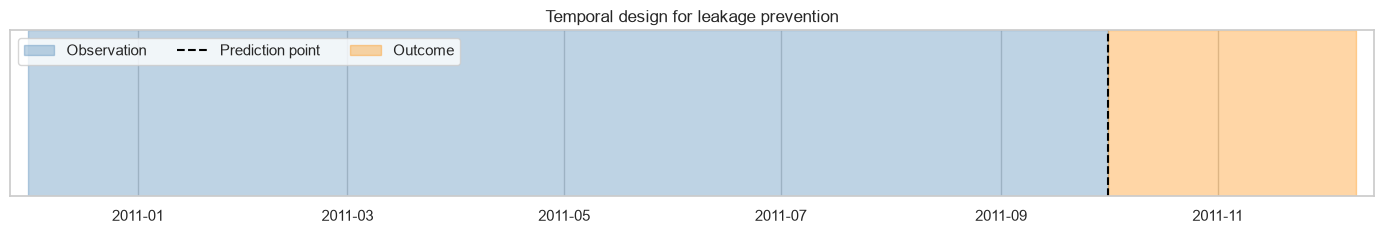

In [10]:
observation = df[(df['InvoiceDate'] >= OBSERVATION_START) & (df['InvoiceDate'] <= OBSERVATION_END)].copy()
outcome = df[(df['InvoiceDate'] >= OUTCOME_START) & (df['InvoiceDate'] <= OUTCOME_END)].copy()
print(f'Observation rows: {len(observation):,}')
print(f'Outcome rows: {len(outcome):,}')

timeline = pd.DataFrame({
    'Window': ['Observation', 'Prediction point', 'Outcome'],
    'Start': [OBSERVATION_START, PREDICTION_POINT, OUTCOME_START],
    'End': [OBSERVATION_END, PREDICTION_POINT, OUTCOME_END],
    'Purpose': ['Build features', 'Freeze information available to model', 'Define active or inactive target'],
})
timeline.to_csv(PROCESSED_PATH / 'temporal_windows.csv', index=False)
display(timeline)

fig, axis = plt.subplots(figsize=(14, 2.5))
axis.axvspan(OBSERVATION_START, OBSERVATION_END, alpha=0.35, color='steelblue', label='Observation')
axis.axvline(PREDICTION_POINT, color='black', linestyle='--', label='Prediction point')
axis.axvspan(OUTCOME_START, OUTCOME_END, alpha=0.35, color='darkorange', label='Outcome')
axis.set_xlim(OBSERVATION_START - pd.Timedelta(days=5), OUTCOME_END + pd.Timedelta(days=5))
axis.set_yticks([])
axis.set_title('Temporal design for leakage prevention')
axis.legend(loc='upper left', ncol=3)
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'temporal_split_design.png', dpi=160, bbox_inches='tight')
plt.show()

In [11]:
outcome_customers = set(outcome['CustomerID'].unique())
observation_customers = sorted(observation['CustomerID'].unique())
target = pd.DataFrame({'CustomerID': observation_customers})
target['inactive_in_outcome_window'] = (~target['CustomerID'].isin(outcome_customers)).astype(int)
target_summary = target['inactive_in_outcome_window'].value_counts().rename_axis('target').reset_index(name='customers')
target_summary['percentage'] = target_summary['customers'] / len(target)
target_summary.to_csv(PROCESSED_PATH / 'target_balance.csv', index=False)
display(target_summary)
print('The positive class is inactive/churned: 1. Target is assigned only after all features are built.')

,target,customers,percentage
0,0,1887,0.515856
1,1,1771,0.484144


The positive class is inactive/churned: 1. Target is assigned only after all features are built.


## 3. Customer-level feature engineering

The feature table has one row per customer and uses observation-window records only. Revenue is net transaction value, while returns are separately measured.

In [12]:
def slope_of_monthly_spend(group):
    monthly = group.groupby('Month')['RevenueModel'].sum()
    if len(monthly) < 2:
        return 0.0
    x = np.arange(len(monthly), dtype=float)
    return float(np.polyfit(x, monthly.to_numpy(dtype=float), 1)[0])

observation = observation.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']).copy()
observation_net_product = (observation.groupby(['CustomerID', 'StockCode'], as_index=False)
    .agg(net_quantity=('Quantity', 'sum'), mean_unit_price=('UnitPrice', 'mean')))
observation_net_product['net_revenue'] = observation_net_product['net_quantity'] * observation_net_product['mean_unit_price']
observation_net_product.to_csv(PROCESSED_PATH / 'net_customer_product_values.csv', index=False)
observation_net_customer = observation_net_product.groupby('CustomerID')['net_revenue'].sum().rename('monetary_total_net').reset_index()

grouped = observation.groupby('CustomerID', sort=True)
features = grouped.agg(
    first_purchase=('InvoiceDate', 'min'),
    last_purchase=('InvoiceDate', 'max'),
    frequency_count=('InvoiceNo', 'nunique'),
    monetary_total=('RevenueModel', 'sum'),
    monetary_avg=('RevenueModel', 'mean'),
    monetary_std=('RevenueModel', 'std'),
    product_diversity=('StockCode', 'nunique'),
    avg_quantity_per_invoice=('QuantityModel', 'mean'),
    return_value=('ReturnValue', 'sum'),
    return_transaction_count=('Quantity', lambda values: int((values < 0).sum())),
    transaction_count=('InvoiceNo', 'size'),
    weekend_ratio=('IsWeekend', 'mean'),
    country=('CountryModel', lambda values: values.mode().iat[0] if not values.mode().empty else 'Other'),
).reset_index()
features = features.drop(columns=['monetary_total']).merge(observation_net_customer, on='CustomerID', how='left')
features = features.rename(columns={'monetary_total_net': 'monetary_total'})

features['monetary_std'] = features['monetary_std'].fillna(0)
features['recency_days'] = (PREDICTION_POINT - features['last_purchase']).dt.total_seconds() / 86400
features['tenure_days'] = (features['last_purchase'] - features['first_purchase']).dt.total_seconds() / 86400
features['days_since_first_purchase'] = (PREDICTION_POINT - features['first_purchase']).dt.total_seconds() / 86400
features['history_days'] = (PREDICTION_POINT - features['first_purchase']).dt.total_seconds() / 86400
features['return_rate'] = features['return_transaction_count'] / features['transaction_count'].replace(0, np.nan)
features['return_rate'] = features['return_rate'].fillna(0)
features['product_diversity_per_invoice'] = features['product_diversity'] / features['frequency_count'].replace(0, np.nan)
features['product_diversity_per_invoice'] = features['product_diversity_per_invoice'].fillna(0)
features['purchase_velocity'] = features['frequency_count'] / (features['history_days'].clip(lower=30) / 30)
features['purchases_per_month'] = features['frequency_count'] / (features['history_days'].clip(lower=30) / 30)
features['spend_per_month'] = features['monetary_total'] / (features['history_days'].clip(lower=30) / 30)
features['recency_ratio'] = features['recency_days'] / features['history_days'].clip(lower=1)

intervals = observation.groupby('CustomerID')['InvoiceDate'].diff().dt.total_seconds().div(86400)
interval_stats = intervals.groupby(observation['CustomerID']).agg(purchase_interval_avg='mean', purchase_interval_std='std').reset_index()
features = features.merge(interval_stats, on='CustomerID', how='left')
features['purchase_interval_avg'] = features['purchase_interval_avg'].fillna(0)
features['purchase_interval_std'] = features['purchase_interval_std'].fillna(0)
features['purchase_interval_cv'] = (features['purchase_interval_std'] / features['purchase_interval_avg'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0)

monthly_std = observation.groupby(['CustomerID', 'Month'])['RevenueModel'].sum().groupby('CustomerID').std().rename('monthly_spend_std').reset_index()
monthly_trend = observation.groupby('CustomerID').apply(slope_of_monthly_spend, include_groups=False).rename('monthly_spend_trend').reset_index()
active_months = observation.groupby('CustomerID')['Month'].nunique().rename('active_months').reset_index()
recent_60 = observation[observation['InvoiceDate'] >= PREDICTION_POINT - pd.Timedelta(days=60)].groupby('CustomerID').agg(
    recent_60d_frequency=('InvoiceNo', 'nunique'), recent_60d_spend=('RevenueModel', 'sum')
).reset_index()
recent_30 = observation[observation['InvoiceDate'] >= PREDICTION_POINT - pd.Timedelta(days=30)].groupby('CustomerID').agg(
    recent_30d_frequency=('InvoiceNo', 'nunique'), recent_30d_spend=('RevenueModel', 'sum')
).reset_index()
features = features.merge(monthly_std, on='CustomerID', how='left').merge(monthly_trend, on='CustomerID', how='left')
features = features.merge(active_months, on='CustomerID', how='left').merge(recent_60, on='CustomerID', how='left').merge(recent_30, on='CustomerID', how='left')
features['monthly_spend_std'] = features['monthly_spend_std'].fillna(0)
features['monthly_spend_trend'] = features['monthly_spend_trend'].fillna(0)
for column in ['active_months', 'recent_60d_frequency', 'recent_60d_spend', 'recent_30d_frequency', 'recent_30d_spend']:
    features[column] = features[column].fillna(0)
features['recent_spend_ratio'] = features['recent_60d_spend'] / features['monetary_total'].abs().replace(0, np.nan)
features['recent_spend_ratio'] = features['recent_spend_ratio'].replace([np.inf, -np.inf], np.nan).fillna(0)
features = features.merge(target, on='CustomerID', how='left')

# Customers with fewer than three invoices do not provide a stable behavioral history.
# They are excluded from supervised modeling, while the raw and cleaned transaction exports remain complete.
history_before_filter = features['CustomerID'].nunique()
features = features[features['frequency_count'] >= 3].copy()
history_filter_summary = pd.DataFrame({
    'criterion': ['minimum unique invoices in observation window'],
    'threshold': [3],
    'customers_before': [history_before_filter],
    'customers_after': [features['CustomerID'].nunique()],
    'customers_removed': [history_before_filter - features['CustomerID'].nunique()],
})
history_filter_summary.to_csv(PROCESSED_PATH / 'customer_history_filter.csv', index=False)
features['CustomerID'] = features['CustomerID'].astype(str)
print(f'Customer feature rows after minimum-history filter: {len(features):,}')
display(history_filter_summary)
display(features.head())

Customer feature rows after minimum-history filter: 1,696


,criterion,threshold,customers_before,customers_after,customers_removed
0,minimum unique invoices in observation window,3,3658,1696,1962


,CustomerID,first_purchase,last_purchase,frequency_count,monetary_avg,monetary_std,product_diversity,avg_quantity_per_invoice,return_value,return_transaction_count,...,purchase_interval_cv,monthly_spend_std,monthly_spend_trend,active_months,recent_60d_frequency,recent_60d_spend,recent_30d_frequency,recent_30d_spend,recent_spend_ratio,inactive_in_outcome_window
1,12347,2010-12-07 14:57:00,2011-08-02 08:48:00,5,21.500484,17.085202,82,11.854839,0.00,0,...,5.529367,123.579764,-34.663,5,1.0,584.91,0.0,0.00,0.209581,0
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,49.370323,37.605036,22,70.870968,0.00,0,...,3.620687,241.072573,-116.424,4,1.0,285.00,1.0,285.00,0.156404,1
4,12352,2011-02-16 12:33:00,2011-09-28 14:58:00,10,13.858500,12.493700,47,4.287500,960.63,10,...,7.248910,164.098479,130.500,3,2.0,557.50,2.0,557.50,0.451900,0
10,12359,2011-01-12 12:43:00,2011-06-03 12:26:00,4,18.905379,12.874270,135,6.627586,35.80,2,...,7.273305,648.094201,94.160,4,0.0,0.00,0.0,0.00,0.000000,0
13,12362,2011-02-17 10:30:00,2011-09-28 12:04:00,7,16.965267,8.825298,121,8.300000,22.80,5,...,5.883672,190.879257,65.209,5,3.0,1273.54,1.0,822.19,0.498540,0


## 4. Leakage checks and feature documentation

In [13]:
feature_columns = [
    'recency_days', 'frequency_count', 'monetary_total', 'monetary_avg', 'monetary_std',
    'tenure_days', 'history_days', 'purchase_interval_avg', 'purchase_interval_std', 'purchase_interval_cv',
    'product_diversity', 'product_diversity_per_invoice', 'avg_quantity_per_invoice',
    'return_rate', 'return_value', 'country', 'weekend_ratio', 'monthly_spend_std',
    'monthly_spend_trend', 'days_since_first_purchase', 'purchase_velocity',
    'purchases_per_month', 'spend_per_month', 'recency_ratio', 'active_months',
]
leakage_checks = pd.DataFrame({
    'Feature': feature_columns,
    'Uses only observation window': ['Yes'] * len(feature_columns),
    'Verification method': ['All source rows filtered to InvoiceDate <= OBSERVATION_END before aggregation'] * len(feature_columns),
})
assert observation['InvoiceDate'].max() <= OBSERVATION_END
assert features['inactive_in_outcome_window'].notna().all()
assert features['CustomerID'].is_unique
leakage_checks.to_csv(DOCS_PATH / 'feature_leakage_checks.csv', index=False)
feature_log = '# Feature Engineering Log\n\n'
feature_log += 'All features are calculated from transactions dated from 2010-12-01 through 2011-09-30. Outcome-window activity is used only for the binary target.\n\n'
feature_log += 'Customers with fewer than three unique invoices are excluded from supervised modeling because their behavioral history is insufficient.\n\n'
feature_log += 'Absolute recent 30-day and 60-day features are retained for audit exploration but excluded from the modeling feature list because their meaning changes with customer age. Tenure-normalized features are used instead.\n\n'
feature_log += leakage_checks.to_string(index=False)
feature_log += '\n\n### Target alternatives considered\n\n'
feature_log += '- No purchase for a fixed number of days: rejected because the outcome window provides a consistent business horizon.\n'
feature_log += '- Revenue below a threshold: rejected because it confounds retention with purchase value.\n'
feature_log += '- Frequency drop: rejected because it requires a customer-specific historical baseline and is less directly actionable.\n'
(DOCS_PATH / 'feature_engineering_log.md').write_text(feature_log, encoding='utf-8')
print('Leakage assertions passed.')

Leakage assertions passed.


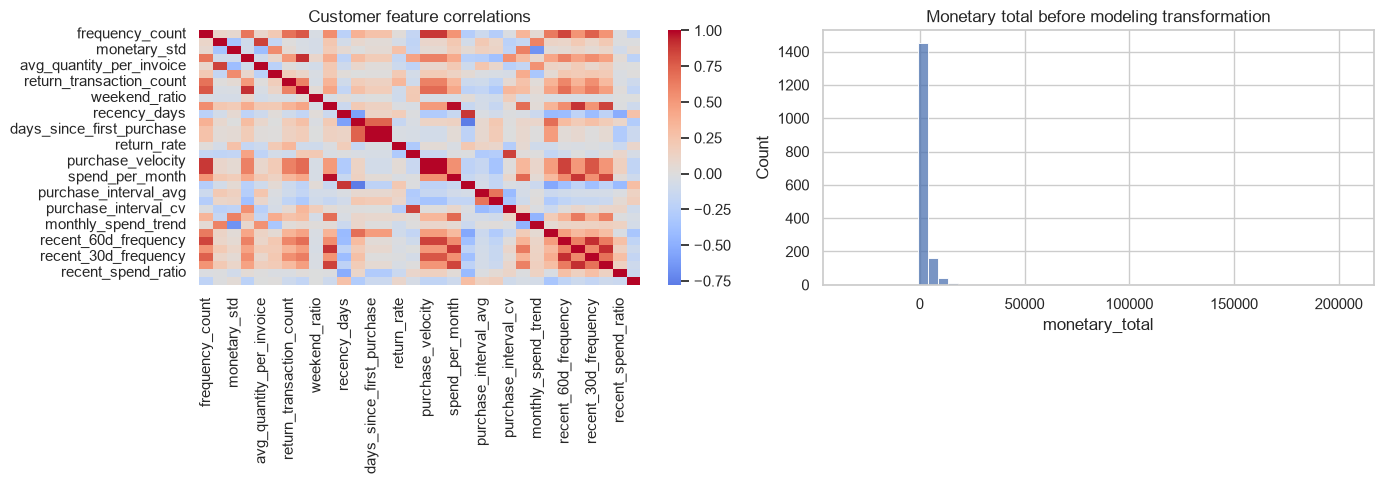

Wrote D:\Year3\final\data\processed\customer_features.csv
Wrote D:\Year3\final\data\processed\cleaned_transactions.csv


In [14]:
numeric_features = features.select_dtypes(include=np.number).columns.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(features[numeric_features].corr(), cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Customer feature correlations')
sns.histplot(data=features, x='monetary_total', bins=50, ax=axes[1])
axes[1].set_title('Monetary total before modeling transformation')
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'feature_distributions_and_correlations.png', dpi=160, bbox_inches='tight')
plt.show()

features.to_csv(PROCESSED_PATH / 'customer_features.csv', index=False)
observation.to_csv(PROCESSED_PATH / 'cleaned_transactions.csv', index=False)
print('Wrote', PROCESSED_PATH / 'customer_features.csv')
print('Wrote', PROCESSED_PATH / 'cleaned_transactions.csv')

## Phase 2 outputs

This notebook writes `cleaned_transactions.csv`, `customer_features.csv`, `target_balance.csv`, `temporal_windows.csv`, `preprocessing_log.md`, `feature_engineering_log.md`, `feature_leakage_checks.csv`, and the temporal and feature diagnostic plots. Phase 3 will train and compare models from `customer_features.csv`.

In [15]:
# Rolling customer snapshots for temporal training and evaluation.
# Each row is one customer at one prediction date; outcome data is never used as a feature.
from pandas.tseries.offsets import DateOffset

SNAPSHOT_DATES = pd.to_datetime([
    '2011-03-31', '2011-04-30', '2011-05-31',
    '2011-06-30', '2011-07-31', '2011-08-31',
])
SNAPSHOT_OBSERVATION_MONTHS = 6
SNAPSHOT_OUTCOME_MONTHS = 2
SNAPSHOT_MIN_PURCHASES = 2
SNAPSHOT_MIN_TENURE_DAYS = 60


def build_snapshot_features(observation_snapshot, prediction_date):
    """Build leakage-safe customer features for one prediction date."""
    if observation_snapshot.empty:
        return pd.DataFrame()
    observation_snapshot = observation_snapshot.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']).copy()
    grouped_snapshot = observation_snapshot.groupby('CustomerID', sort=True)
    snapshot_features = grouped_snapshot.agg(
        first_purchase=('InvoiceDate', 'min'),
        last_purchase=('InvoiceDate', 'max'),
        frequency_count=('InvoiceNo', 'nunique'),
        monetary_total=('RevenueModel', 'sum'),
        monetary_avg=('RevenueModel', 'mean'),
        monetary_std=('RevenueModel', 'std'),
        product_diversity=('StockCode', 'nunique'),
        product_diversity_per_invoice=('StockCode', lambda values: values.nunique()),
        avg_quantity_per_invoice=('QuantityModel', 'mean'),
        return_value=('ReturnValue', 'sum'),
        return_transaction_count=('Quantity', lambda values: int((values < 0).sum())),
        transaction_count=('InvoiceNo', 'size'),
        weekend_ratio=('IsWeekend', 'mean'),
        country=('CountryModel', lambda values: values.mode().iat[0] if not values.mode().empty else 'Other'),
    ).reset_index()
    snapshot_features['monetary_std'] = snapshot_features['monetary_std'].fillna(0)
    snapshot_features['recency_days'] = (prediction_date - snapshot_features['last_purchase']).dt.total_seconds() / 86400
    snapshot_features['tenure_days'] = (snapshot_features['last_purchase'] - snapshot_features['first_purchase']).dt.total_seconds() / 86400
    snapshot_features['history_days'] = (prediction_date - snapshot_features['first_purchase']).dt.total_seconds() / 86400
    snapshot_features['days_since_first_purchase'] = snapshot_features['history_days']
    snapshot_features['return_rate'] = snapshot_features['return_transaction_count'] / snapshot_features['transaction_count'].replace(0, np.nan)
    snapshot_features['return_rate'] = snapshot_features['return_rate'].fillna(0)
    snapshot_features['product_diversity_per_invoice'] = snapshot_features['product_diversity_per_invoice'] / snapshot_features['frequency_count'].replace(0, np.nan)
    snapshot_features['product_diversity_per_invoice'] = snapshot_features['product_diversity_per_invoice'].fillna(0)
    snapshot_features['purchase_velocity'] = snapshot_features['frequency_count'] / (snapshot_features['history_days'].clip(lower=30) / 30)
    snapshot_features['purchases_per_month'] = snapshot_features['purchase_velocity']
    snapshot_features['spend_per_month'] = snapshot_features['monetary_total'] / (snapshot_features['history_days'].clip(lower=30) / 30)
    snapshot_features['recency_ratio'] = snapshot_features['recency_days'] / snapshot_features['history_days'].clip(lower=1)

    invoice_dates = observation_snapshot.drop_duplicates(['CustomerID', 'InvoiceNo']).sort_values(['CustomerID','InvoiceDate'])
    intervals = invoice_dates.groupby('CustomerID')['InvoiceDate'].diff().dt.total_seconds().div(86400)
    interval_stats = intervals.groupby(invoice_dates['CustomerID']).agg(
        purchase_interval_avg='mean', purchase_interval_std='std').reset_index()
    snapshot_features = snapshot_features.merge(interval_stats, on='CustomerID', how='left')
    snapshot_features['purchase_interval_avg'] = snapshot_features['purchase_interval_avg'].fillna(0)
    snapshot_features['purchase_interval_std'] = snapshot_features['purchase_interval_std'].fillna(0)
    snapshot_features['purchase_interval_cv'] = (
        snapshot_features['purchase_interval_std'] / snapshot_features['purchase_interval_avg'].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan).fillna(0)
    monthly_spend = observation_snapshot.assign(SnapshotMonth=observation_snapshot['InvoiceDate'].dt.to_period('M'))
    monthly_stats = monthly_spend.groupby(['CustomerID', 'SnapshotMonth'])['RevenueModel'].sum()
    monthly_std = monthly_stats.groupby('CustomerID').std().rename('monthly_spend_std').reset_index()
    snapshot_features = snapshot_features.merge(monthly_std, on='CustomerID', how='left')
    snapshot_features['monthly_spend_std'] = snapshot_features['monthly_spend_std'].fillna(0)
    snapshot_features['monthly_spend_trend'] = 0.0
    snapshot_features['active_months'] = observation_snapshot.assign(
        SnapshotMonth=observation_snapshot['InvoiceDate'].dt.to_period('M')
    ).groupby('CustomerID')['SnapshotMonth'].nunique().reindex(snapshot_features['CustomerID']).to_numpy()
    snapshot_features['active_months'] = snapshot_features['active_months'].fillna(0)
    return snapshot_features


snapshot_frames = []
for prediction_date in SNAPSHOT_DATES:
    observation_start = prediction_date - DateOffset(months=SNAPSHOT_OBSERVATION_MONTHS)
    outcome_end = prediction_date + DateOffset(months=SNAPSHOT_OUTCOME_MONTHS)
    observation_snapshot = df[(df['InvoiceDate'] >= observation_start) & (df['InvoiceDate'] < prediction_date)].copy()
    # Learn transformations from this snapshot's past only, never the full future dataset.
    qcap = observation_snapshot.loc[observation_snapshot.Quantity > 0, 'Quantity'].quantile(.99)
    pcap = observation_snapshot.UnitPrice.quantile(.99)
    observation_snapshot['QuantityModel'] = observation_snapshot.Quantity.clip(upper=qcap)
    observation_snapshot['UnitPriceModel'] = observation_snapshot.UnitPrice.clip(upper=pcap)
    observation_snapshot['RevenueModel'] = observation_snapshot.QuantityModel * observation_snapshot.UnitPriceModel
    top = observation_snapshot.Country.value_counts().head(5).index
    observation_snapshot['CountryModel'] = observation_snapshot.Country.where(observation_snapshot.Country.isin(top), 'Other')
    outcome_snapshot = df[(df['InvoiceDate'] >= prediction_date) & (df['InvoiceDate'] < outcome_end)].copy()
    snapshot_features = build_snapshot_features(observation_snapshot, prediction_date)
    if snapshot_features.empty:
        continue
    active_customers = set(outcome_snapshot.loc[(outcome_snapshot.Quantity > 0) & ~outcome_snapshot.IsCancellation, 'CustomerID'].unique())
    snapshot_features['inactive_in_outcome_window'] = (~snapshot_features['CustomerID'].isin(active_customers)).astype(int)
    snapshot_features = snapshot_features[
        (snapshot_features['frequency_count'] >= SNAPSHOT_MIN_PURCHASES)
        & (snapshot_features['history_days'] >= SNAPSHOT_MIN_TENURE_DAYS)
    ].copy()
    snapshot_features['prediction_date'] = prediction_date
    snapshot_features['snapshot_id'] = f'snap_{prediction_date:%Y%m%d}'
    snapshot_frames.append(snapshot_features)

snapshot_data = pd.concat(snapshot_frames, ignore_index=True)
snapshot_data['CustomerID'] = snapshot_data['CustomerID'].astype(str)
snapshot_data.to_csv(PROCESSED_PATH / 'customer_snapshot_features.csv', index=False)
snapshot_summary = snapshot_data.groupby('snapshot_id').agg(
    prediction_date=('prediction_date', 'first'), records=('CustomerID', 'size'),
    customers=('CustomerID', 'nunique'), inactive_rate=('inactive_in_outcome_window', 'mean')
).reset_index()
snapshot_summary.to_csv(PROCESSED_PATH / 'snapshot_summary.csv', index=False)
print(f'Combined customer-snapshot records: {len(snapshot_data):,}')
print(f'Unique customers across snapshots: {snapshot_data["CustomerID"].nunique():,}')
print(f'Snapshots created: {snapshot_data["snapshot_id"].nunique()}')
display(snapshot_summary)

Combined customer-snapshot records: 8,004
Unique customers across snapshots: 1,994
Snapshots created: 6


,snapshot_id,prediction_date,records,customers,inactive_rate
0,snap_20110331,2011-03-31,854,854,0.359485
1,snap_20110430,2011-04-30,1122,1122,0.392157
2,snap_20110531,2011-05-31,1412,1412,0.443343
3,snap_20110630,2011-06-30,1460,1460,0.456849
4,snap_20110731,2011-07-31,1553,1553,0.426272
5,snap_20110831,2011-08-31,1603,1603,0.380536


## Recent positive-purchase features
The model keeps the original customer cohort and target for comparison. Additional signals use only positive, non-cancelled invoices before each cutoff: 30/60/90-day activity, order-level value and quantity, recent changes and overdue purchasing. Existing legacy aggregates remain identifiable; recent signals never use globally clipped columns.


In [16]:
import sys
sys.path.insert(0, str(PROJECT_ROOT/'src'))
from model_workflow import enrich_snapshots, RECENT_FEATURES
snapshot_data = enrich_snapshots(snapshot_data, df)
snapshot_data.to_csv(PROCESSED_PATH/'customer_snapshot_features.csv', index=False)
display(snapshot_data[['CustomerID','prediction_date']+RECENT_FEATURES].head())


,CustomerID,prediction_date,positive_recency_days,positive_invoice_count,positive_order_value,positive_quantity_per_invoice,days_overdue,orders_30d,orders_60d,orders_90d,spend_30d,spend_60d,spend_90d,order_trend,spend_trend
0,12346,2011-03-31,71.582639,1.0,77183.600,74215.000000,NaN,0.0,0.0,1.0,0.00,0.00,77183.60,1.0,1.000000
1,12347,2011-03-31,63.395833,2.0,593.590,317.000000,1.268392,0.0,0.0,1.0,0.00,0.00,475.39,1.0,1.000000
2,12348,2011-03-31,64.554167,2.0,560.120,927.500000,1.628186,0.0,0.0,1.0,0.00,0.00,227.44,1.0,1.000000
3,12359,2011-03-31,51.381250,2.0,1193.205,304.500000,1.969469,0.0,1.0,2.0,0.00,1838.91,2386.41,0.5,0.000544
4,12370,2011-03-31,20.466667,3.0,934.220,657.333333,0.476007,1.0,1.0,1.0,938.39,938.39,938.39,2.0,939.390000



---

# Part 6: Logistic Regression - Complete Analysis

*Source: `03_01_logistic_regression.ipynb`*

*Original cells: 18 | Code: 8 | Markdown: 10*


# Optimized Logistic Regression

This notebook uses the final optimized settings and frozen prediction threshold for this model. It displays training, validation and test accuracy, optimization settings, and fitting diagnostics. The combined comparison remains in `FINAL_Four_Optimized_Models.ipynb`. Test results are reused-holdout estimates, not independent validation.

In [17]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from sklearn.base import clone
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0, str(root/'src'))
from model_workflow import paths, load_features, matrix, TARGET, metrics
MODEL = 'logistic_regression'
folder = root/'outputs/final_four'
bundle = joblib.load(folder/f'{MODEL}.joblib')
model = bundle['pipeline']
metadata = bundle['metadata']
threshold = metadata['Threshold']
data, fingerprint = load_features(paths(root)['processed'])
assert fingerprint == metadata['fingerprint'], 'Data changed; revalidate optimization before use.'
print('Model:', MODEL)
print('Optimized variant:', metadata['Source'])
print('Frozen threshold:', threshold)
print('Selected overall:', metadata['selected'])

Model: logistic_regression
Optimized variant: optimized_logistic_regression
Frozen threshold: 0.425
Selected overall: False


## Optimized pipeline and settings

Preprocessing is part of the fitted pipeline. Hyperparameters were selected using training cross-validation; the operating threshold was selected on validation data.

In [18]:
display(model)
display(pd.DataFrame(list(model.named_steps['model'].get_params().items()), columns=['Parameter','Value']))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prepare', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('country', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that us

,Parameter,Value
0,C,0.01
1,class_weight,None
2,dual,False
3,fit_intercept,True
4,intercept_scaling,1
5,l1_ratio,0.0
6,max_iter,3000
7,n_jobs,None
8,penalty,deprecated
9,random_state,42


### Why the final settings were retained

C=0.01 applies strong regularization to transformed behavioral inputs; max_iter=3000 provides an optimization iteration budget. The retained optimized_logistic_regression variant passed the fitting audit and reached 68.29% validation accuracy. These values are supported by the retained variant comparison, not claimed as the unrestricted best possible settings.


## Hyperparameter tuning evidence (loaded historical results)

The final fitted hyperparameters are displayed above. The table below loads the retained **updated optimization search**, including the tested parameter distributions, best mean CV score, selected trial and its three fold scores. These later trials were compared with earlier incumbent variants; the final bundle did not necessarily come from the updated search. The original incumbent per-trial search files are no longer in the clean package, so the later trial must not be described as the exact origin of the final model.

Search: RandomizedSearchCV, at most 32 configurations, random_state=73; three customer-grouped folds, shuffle=True, random_state=42. All CV accuracies here use threshold 0.50. The training-only selection rule requires a train–CV gap ≤5 percentage points, CV improvement ≥3 points over the majority baseline, and CV within 1 point of the search best; near-ties within 0.2 points prefer a smaller gap. Thus the selected trial can differ from the highest raw CV score.


In [19]:
from tuning_workflow import historical_search, GRIDS, load_cv, frozen_cv, tune
from accuracy_experiments import candidates, make_pipeline, preparation
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid

# Parameter distributions for the retained historical UPDATED search.
historical_name = 'optimized_' + MODEL
historical_spaces = {name: space for name, pipeline, space in candidates()}
historical_spaces['optimized_gradient_boosting'] = {
    'prepare': [preparation(True), preparation(False)],
    'model__n_estimators': [60, 120, 240],
    'model__learning_rate': [.025, .05, .1],
    'model__max_depth': [1, 2, 3],
    'model__min_samples_leaf': [40, 80, 120],
    'model__subsample': [.7, 1.0],
}
display(pd.DataFrame([{'Parameter': k, 'Historical distribution': str(v)}
                      for k, v in historical_spaces[historical_name].items()]))
historical_results, historical_index = historical_search(MODEL, root)
trial = historical_results.iloc[historical_index]
print('LOADED historical updated-search evidence; no tuning performed by this cell.')
print('Tested configurations:', len(historical_results))
print('Best historical search CV accuracy:', f'{historical_results.mean_test_accuracy.max():.4%}')
print('Rule-selected historical trial CV accuracy:', f'{trial.mean_test_accuracy:.4%}')
display(trial[[c for c in historical_results.columns if c.startswith('param_')]].to_frame('Selected historical trial'))
display(pd.DataFrame({'Fold': [1, 2, 3],
    'Historical selected-trial CV accuracy': [trial[f'split{i}_test_accuracy'] for i in range(3)],
    'Historical selected-trial training accuracy': [trial[f'split{i}_train_accuracy'] for i in range(3)]}))
family_records = pd.read_csv(root/'outputs/evidence/optimization/validation_comparison.csv')
variant_names = [MODEL, 'optimized_'+MODEL, 'updated_optimized_'+MODEL]
display(family_records[family_records.Model.isin(variant_names)][
    ['Model', 'Validation accuracy', 'CV accuracy', 'Threshold', 'Eligible']])
print('Final retained source variant:', metadata['Source'])
print('The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.')


,Parameter,Historical distribution
0,prepare,"[ColumnTransformer(transformers=[('numeric',\n..."
1,model__C,"[0.001, 0.01, 0.1, 1, 10]"
2,model__class_weight,"[None, 'balanced']"


LOADED historical updated-search evidence; no tuning performed by this cell.
Tested configurations: 20
Best historical search CV accuracy: 69.3338%
Rule-selected historical trial CV accuracy: 69.1826%


,Selected historical trial
param_prepare,"ColumnTransformer(transformers=[('numeric',\n ..."
param_model__class_weight,NaN
param_model__C,0.01


,Fold,Historical selected-trial CV accuracy,Historical selected-trial training accuracy
0,1,0.717325,0.701062
1,2,0.689970,0.710167
2,3,0.668182,0.729483


,Model,Validation accuracy,CV accuracy,Threshold,Eligible
0,logistic_regression,0.679452,0.691822,0.375,True
4,optimized_logistic_regression,0.682877,0.691826,0.425,True
11,updated_optimized_logistic_regression,0.682877,0.691826,0.425,True


Final retained source variant: optimized_logistic_regression
The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.


## Cross-validation of the final model settings

The saved evidence below was **newly computed during this revision**, by cloning the final pipeline and fitting it separately in each of three StratifiedGroupKFold training folds (seed 42). At ordinary notebook execution it is **loaded**, not recomputed. Customer IDs never overlap across the train/held-out sides of a fold; imputation, encoding and scaling are refitted inside each clone. Fold sizes and customer counts are included. The CSV and provenance JSON identify the data fingerprint, bundle hash and software versions.

Both default 0.50 and frozen operating thresholds are shown. Their means are unweighted averages across three folds, not pooled accuracy. This seed-42 diagnostic differs from the older seed-137 frozen-threshold audit; do not mix their scores. Set RECOMPUTE_CV=True to recompute these diagnostics without changing the final fitted bundles.


In [20]:
RECOMPUTE_CV = False
if RECOMPUTE_CV:
    cv_folds = frozen_cv(MODEL, root)
    print('NEWLY COMPUTED: clones refitted on three training folds.')
else:
    cv_folds, cv_provenance = load_cv(MODEL, root)
    print('LOADED: previously computed final-settings CV evidence; no training in this cell.')
    print(cv_provenance)
display(cv_folds)
cv_summary = cv_folds.groupby('threshold')[['train_accuracy', 'cv_accuracy']].mean()
cv_summary['train_cv_gap'] = cv_summary.train_accuracy - cv_summary.cv_accuracy
display(cv_summary)
print('Final settings mean CV accuracy (0.50):', f"{cv_summary.loc[0.5, 'cv_accuracy']:.4%}")


LOADED: previously computed final-settings CV evidence; no training in this cell.
{'model': 'logistic_regression', 'fingerprint': '4d1cb943f51e641ec287113ab684d7345a7c84bf1b93f8458088adcdec90b73d', 'bundle_sha256': '6243c4efb4775db5541e7158155461e62073b8663153d2a1d935d46b5f7d3e6c', 'python': '3.12.14', 'sklearn': '1.9.1', 'folds': 3, 'fold_seed': 42, 'status': 'Newly computed diagnostic; clones fitted only on training folds', 'limitation': 'Not nested CV or independent temporal validation; holdouts were reused during development.'}


,fold,threshold,training_rows,heldout_rows,training_customers,heldout_customers,train_accuracy,cv_accuracy
0,1,0.425,1318,658,749,373,0.685129,0.703647
1,1,0.500,1318,658,749,373,0.701062,0.717325
2,2,0.425,1318,658,748,374,0.691199,0.679331
3,2,0.500,1318,658,748,374,0.710167,0.689970
4,3,0.425,1316,660,747,375,0.704407,0.665152
5,3,0.500,1316,660,747,375,0.729483,0.668182


,train_accuracy,cv_accuracy,train_cv_gap
threshold,,,
0.425,0.693578,0.682710,0.010868
0.500,0.713571,0.691826,0.021745


Final settings mean CV accuracy (0.50): 69.1826%


## Reproduce training and tuning (optional)

The clean-package rerun below uses the supplied final pipeline as an **unfitted template**: sklearn.clone discards all learned state. The displayed rerun grid includes the published setting and nearby alternatives. It fixes the final feature/preprocessing design; it is an explicit new reproducible experiment, not an exact replay of every historical feature/search trial. It requires only the included snapshot CSV, final bundle and runtime helpers.

RUN_TUNING=False loads no new candidate. Set it to True for up to 32 randomized configurations with three grouped folds. Candidate selection uses training CV, then June validation selects its threshold. No test scores enter the rerun. Results, chosen settings, fold scores and a candidate bundle are written to outputs/reproduction/<model>/; published final models stay unchanged. A candidate failing screening is recorded as rejected. A future promotion would require repeated and threshold-matched audits plus independent future-period evidence.


In [21]:
display(pd.DataFrame([{'Parameter': k, 'Rerun grid': str(v)} for k, v in GRIDS[MODEL].items()]))
RUN_TUNING = False
if RUN_TUNING:
    rerun_results, rerun_record = tune(MODEL, root, n_iter=32)
    print('NEWLY COMPUTED tuning experiment; original published model unchanged.')
    print(json.dumps(rerun_record, indent=2))
    display(rerun_results.sort_values('mean_test_accuracy', ascending=False).head())
else:
    print('Tuning not run. Set RUN_TUNING=True or use:')
    print(f'python src/tuning_workflow.py --model {MODEL} --mode tune --n-iter 32')


,Parameter,Rerun grid
0,model__C,"[0.001, 0.01, 0.1, 1, 10]"
1,model__class_weight,"[None, 'balanced']"


Tuning not run. Set RUN_TUNING=True or use:
python src/tuning_workflow.py --model logistic_regression --mode tune --n-iter 32


## Validation limitations

Grouped CV estimates performance on held-out customers **within the training period**. It does not reproduce seasonal change or replace independent temporal validation. Customers may recur between the March/April training snapshots, June validation and August test snapshots; grouping applies within CV, not across those temporal partitions. Search CV is reused to choose settings, so its best score is not an unbiased nested-CV estimate. Repeated diagnostics are not independent experiments.

Validation and test holdouts were inspected repeatedly during project development. Their reported scores are reused-holdout evidence. The validation-selected threshold and variant can overfit validation even when CV gaps are small. Snapshot-level caps and country grouping were calculated from past cohorts, not independently inside customer CV folds. A genuinely new future period is needed for independent confirmation.


## Optional training with the frozen settings

Set `RETRAIN=True` to refit the same optimized pipeline on the training split only. This does not rerun hyperparameter search, change thresholds, or overwrite the published model files.

In [22]:
RETRAIN = False
if RETRAIN:
    training = data[data.split.eq('train')]
    model = clone(bundle['pipeline']).fit(matrix(training), training[TARGET])
    print('Refitted frozen settings on training data only.')
else:
    print('Using the verified saved optimized model.')

Using the verified saved optimized model.


## Training and test accuracy

Every split uses the same frozen threshold. Test scores are for reporting only; do not adjust parameters from them.

In [23]:
rows = []
for split in ['train','validation','test']:
    part = data[data.split.eq(split)]
    probability = model.predict_proba(matrix(part))[:,1]
    result = metrics(MODEL, part[TARGET], probability, threshold)
    result['Split'] = split
    rows.append(result)
results = pd.DataFrame(rows).set_index('Split')
display(results[['Accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC','Threshold']])
print(f"Training accuracy: {results.loc['train','Accuracy']:.2%}")
print(f"Test accuracy: {results.loc['test','Accuracy']:.2%}")
if not RETRAIN:
    expected = pd.read_csv(folder/'accuracy_summary.csv').set_index('Model').loc[MODEL]
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy'),('test','Test accuracy')]:
        assert np.isclose(results.loc[split,'Accuracy'], expected[column])
    print('Verified against the final comparison table.')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold
Split,,,,,,,
train,0.686741,0.576190,0.647925,0.609956,0.763083,0.642559,0.425
validation,0.682877,0.665584,0.614693,0.639127,0.748720,0.697009,0.425
test,0.673737,0.560333,0.662295,0.607062,0.730448,0.580260,0.425


Training accuracy: 68.67%
Test accuracy: 67.37%
Verified against the final comparison table.


## Fitting checks

The CV gap below is from the saved optimized model audit using its frozen threshold. Positive gaps alone do not prove harmful overfitting. The 5-point limit is a screening heuristic; a small gap does not prove absence of underfitting. Historical CV diagnostics must be rerun if settings or training data change.

In [24]:
print(f"Train-validation gap: {100*(results.loc['train','Accuracy']-results.loc['validation','Accuracy']):.2f} percentage points")
print(f"Train-test gap: {100*(results.loc['train','Accuracy']-results.loc['test','Accuracy']):.2f} percentage points")
print(f"Saved threshold-matched CV gap: {100*metadata['Threshold-matched CV gap']:.2f} percentage points")
print('Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.')

Train-validation gap: 0.39 percentage points
Train-test gap: 1.30 percentage points
Saved threshold-matched CV gap: 0.81 percentage points
Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.



---

# Part 7: Decision Tree - Complete Analysis

*Source: `03_02_decision_tree.ipynb`*

*Original cells: 18 | Code: 8 | Markdown: 10*


# Optimized Decision Tree

This notebook uses the final optimized settings and frozen prediction threshold for this model. It displays training, validation and test accuracy, optimization settings, and fitting diagnostics. The combined comparison remains in `FINAL_Four_Optimized_Models.ipynb`. Test results are reused-holdout estimates, not independent validation.

In [25]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from sklearn.base import clone
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0, str(root/'src'))
from model_workflow import paths, load_features, matrix, TARGET, metrics
MODEL = 'decision_tree'
folder = root/'outputs/final_four'
bundle = joblib.load(folder/f'{MODEL}.joblib')
model = bundle['pipeline']
metadata = bundle['metadata']
threshold = metadata['Threshold']
data, fingerprint = load_features(paths(root)['processed'])
assert fingerprint == metadata['fingerprint'], 'Data changed; revalidate optimization before use.'
print('Model:', MODEL)
print('Optimized variant:', metadata['Source'])
print('Frozen threshold:', threshold)
print('Selected overall:', metadata['selected'])

Model: decision_tree
Optimized variant: decision_tree
Frozen threshold: 0.425
Selected overall: False


## Optimized pipeline and settings

Preprocessing is part of the fitted pipeline. Hyperparameters were selected using training cross-validation; the operating threshold was selected on validation data.

In [26]:
display(model)
display(pd.DataFrame(list(model.named_steps['model'].get_params().items()), columns=['Parameter','Value']))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['recency_days','frequency_count','monetary_total',...,'spend_90d', 'order_trend','spend_trend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('country', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

,Parameter,Value
0,ccp_alpha,0.005
1,class_weight,None
2,criterion,gini
3,max_depth,2
4,max_features,None
5,max_leaf_nodes,None
6,min_impurity_decrease,0.0
7,min_samples_leaf,30
8,min_samples_split,2
9,min_weight_fraction_leaf,0.0


### Why the final settings were retained

max_depth=2, min_samples_leaf=30 and ccp_alpha=0.005 constrain tree complexity and prune weak branches. The retained decision_tree variant passed the fitting audit and achieved 66.10% validation accuracy. The selected historical updated trial may differ; the final family choice uses the eligible validation comparison.


## Hyperparameter tuning evidence (loaded historical results)

The final fitted hyperparameters are displayed above. The table below loads the retained **updated optimization search**, including the tested parameter distributions, best mean CV score, selected trial and its three fold scores. These later trials were compared with earlier incumbent variants; the final bundle did not necessarily come from the updated search. The original incumbent per-trial search files are no longer in the clean package, so the later trial must not be described as the exact origin of the final model.

Search: RandomizedSearchCV, at most 32 configurations, random_state=73; three customer-grouped folds, shuffle=True, random_state=42. All CV accuracies here use threshold 0.50. The training-only selection rule requires a train–CV gap ≤5 percentage points, CV improvement ≥3 points over the majority baseline, and CV within 1 point of the search best; near-ties within 0.2 points prefer a smaller gap. Thus the selected trial can differ from the highest raw CV score.


In [27]:
from tuning_workflow import historical_search, GRIDS, load_cv, frozen_cv, tune
from accuracy_experiments import candidates, make_pipeline, preparation
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid

# Parameter distributions for the retained historical UPDATED search.
historical_name = 'optimized_' + MODEL
historical_spaces = {name: space for name, pipeline, space in candidates()}
historical_spaces['optimized_gradient_boosting'] = {
    'prepare': [preparation(True), preparation(False)],
    'model__n_estimators': [60, 120, 240],
    'model__learning_rate': [.025, .05, .1],
    'model__max_depth': [1, 2, 3],
    'model__min_samples_leaf': [40, 80, 120],
    'model__subsample': [.7, 1.0],
}
display(pd.DataFrame([{'Parameter': k, 'Historical distribution': str(v)}
                      for k, v in historical_spaces[historical_name].items()]))
historical_results, historical_index = historical_search(MODEL, root)
trial = historical_results.iloc[historical_index]
print('LOADED historical updated-search evidence; no tuning performed by this cell.')
print('Tested configurations:', len(historical_results))
print('Best historical search CV accuracy:', f'{historical_results.mean_test_accuracy.max():.4%}')
print('Rule-selected historical trial CV accuracy:', f'{trial.mean_test_accuracy:.4%}')
display(trial[[c for c in historical_results.columns if c.startswith('param_')]].to_frame('Selected historical trial'))
display(pd.DataFrame({'Fold': [1, 2, 3],
    'Historical selected-trial CV accuracy': [trial[f'split{i}_test_accuracy'] for i in range(3)],
    'Historical selected-trial training accuracy': [trial[f'split{i}_train_accuracy'] for i in range(3)]}))
family_records = pd.read_csv(root/'outputs/evidence/optimization/validation_comparison.csv')
variant_names = [MODEL, 'optimized_'+MODEL, 'updated_optimized_'+MODEL]
display(family_records[family_records.Model.isin(variant_names)][
    ['Model', 'Validation accuracy', 'CV accuracy', 'Threshold', 'Eligible']])
print('Final retained source variant:', metadata['Source'])
print('The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.')


,Parameter,Historical distribution
0,prepare,"[ColumnTransformer(transformers=[('numeric',\n..."
1,model__max_depth,"[2, 3, 4, 6]"
2,model__min_samples_leaf,"[25, 50, 100]"
3,model__ccp_alpha,"[0.001, 0.005, 0.01]"
4,model__class_weight,"[None, 'balanced']"


LOADED historical updated-search evidence; no tuning performed by this cell.
Tested configurations: 32
Best historical search CV accuracy: 68.1186%
Rule-selected historical trial CV accuracy: 68.1186%


,Selected historical trial
param_prepare,"ColumnTransformer(transformers=[('numeric',\n ..."
param_model__min_samples_leaf,25
param_model__max_depth,4
param_model__class_weight,NaN
param_model__ccp_alpha,0.01


,Fold,Historical selected-trial CV accuracy,Historical selected-trial training accuracy
0,1,0.686930,0.698027
1,2,0.686930,0.688164
2,3,0.669697,0.692249


,Model,Validation accuracy,CV accuracy,Threshold,Eligible
1,decision_tree,0.660959,0.682196,0.425,True
7,optimized_decision_tree,0.660959,0.681186,0.425,True
14,updated_optimized_decision_tree,0.660959,0.681186,0.425,True


Final retained source variant: decision_tree
The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.


## Cross-validation of the final model settings

The saved evidence below was **newly computed during this revision**, by cloning the final pipeline and fitting it separately in each of three StratifiedGroupKFold training folds (seed 42). At ordinary notebook execution it is **loaded**, not recomputed. Customer IDs never overlap across the train/held-out sides of a fold; imputation, encoding and scaling are refitted inside each clone. Fold sizes and customer counts are included. The CSV and provenance JSON identify the data fingerprint, bundle hash and software versions.

Both default 0.50 and frozen operating thresholds are shown. Their means are unweighted averages across three folds, not pooled accuracy. This seed-42 diagnostic differs from the older seed-137 frozen-threshold audit; do not mix their scores. Set RECOMPUTE_CV=True to recompute these diagnostics without changing the final fitted bundles.


In [28]:
RECOMPUTE_CV = False
if RECOMPUTE_CV:
    cv_folds = frozen_cv(MODEL, root)
    print('NEWLY COMPUTED: clones refitted on three training folds.')
else:
    cv_folds, cv_provenance = load_cv(MODEL, root)
    print('LOADED: previously computed final-settings CV evidence; no training in this cell.')
    print(cv_provenance)
display(cv_folds)
cv_summary = cv_folds.groupby('threshold')[['train_accuracy', 'cv_accuracy']].mean()
cv_summary['train_cv_gap'] = cv_summary.train_accuracy - cv_summary.cv_accuracy
display(cv_summary)
print('Final settings mean CV accuracy (0.50):', f"{cv_summary.loc[0.5, 'cv_accuracy']:.4%}")


LOADED: previously computed final-settings CV evidence; no training in this cell.
{'model': 'decision_tree', 'fingerprint': '4d1cb943f51e641ec287113ab684d7345a7c84bf1b93f8458088adcdec90b73d', 'bundle_sha256': 'b50e5d564dedeb5e7483fde54f4df03db32a6854cfc99ca46582b8d95f32a092', 'python': '3.12.14', 'sklearn': '1.9.1', 'folds': 3, 'fold_seed': 42, 'status': 'Newly computed diagnostic; clones fitted only on training folds', 'limitation': 'Not nested CV or independent temporal validation; holdouts were reused during development.'}


,fold,threshold,training_rows,heldout_rows,training_customers,heldout_customers,train_accuracy,cv_accuracy
0,1,0.425,1318,658,749,373,0.698027,0.686930
1,1,0.500,1318,658,749,373,0.698027,0.686930
2,2,0.425,1318,658,748,374,0.656297,0.645897
3,2,0.500,1318,658,748,374,0.688164,0.686930
4,3,0.425,1316,660,747,375,0.626900,0.601515
5,3,0.500,1316,660,747,375,0.693769,0.672727


,train_accuracy,cv_accuracy,train_cv_gap
threshold,,,
0.425,0.660408,0.644781,0.015628
0.500,0.693320,0.682196,0.011124


Final settings mean CV accuracy (0.50): 68.2196%


## Reproduce training and tuning (optional)

The clean-package rerun below uses the supplied final pipeline as an **unfitted template**: sklearn.clone discards all learned state. The displayed rerun grid includes the published setting and nearby alternatives. It fixes the final feature/preprocessing design; it is an explicit new reproducible experiment, not an exact replay of every historical feature/search trial. It requires only the included snapshot CSV, final bundle and runtime helpers.

RUN_TUNING=False loads no new candidate. Set it to True for up to 32 randomized configurations with three grouped folds. Candidate selection uses training CV, then June validation selects its threshold. No test scores enter the rerun. Results, chosen settings, fold scores and a candidate bundle are written to outputs/reproduction/<model>/; published final models stay unchanged. A candidate failing screening is recorded as rejected. A future promotion would require repeated and threshold-matched audits plus independent future-period evidence.


In [29]:
display(pd.DataFrame([{'Parameter': k, 'Rerun grid': str(v)} for k, v in GRIDS[MODEL].items()]))
RUN_TUNING = False
if RUN_TUNING:
    rerun_results, rerun_record = tune(MODEL, root, n_iter=32)
    print('NEWLY COMPUTED tuning experiment; original published model unchanged.')
    print(json.dumps(rerun_record, indent=2))
    display(rerun_results.sort_values('mean_test_accuracy', ascending=False).head())
else:
    print('Tuning not run. Set RUN_TUNING=True or use:')
    print(f'python src/tuning_workflow.py --model {MODEL} --mode tune --n-iter 32')


,Parameter,Rerun grid
0,model__max_depth,"[2, 3, 4, 6]"
1,model__min_samples_leaf,"[25, 30, 50, 100]"
2,model__ccp_alpha,"[0.001, 0.005, 0.01]"


Tuning not run. Set RUN_TUNING=True or use:
python src/tuning_workflow.py --model decision_tree --mode tune --n-iter 32


## Validation limitations

Grouped CV estimates performance on held-out customers **within the training period**. It does not reproduce seasonal change or replace independent temporal validation. Customers may recur between the March/April training snapshots, June validation and August test snapshots; grouping applies within CV, not across those temporal partitions. Search CV is reused to choose settings, so its best score is not an unbiased nested-CV estimate. Repeated diagnostics are not independent experiments.

Validation and test holdouts were inspected repeatedly during project development. Their reported scores are reused-holdout evidence. The validation-selected threshold and variant can overfit validation even when CV gaps are small. Snapshot-level caps and country grouping were calculated from past cohorts, not independently inside customer CV folds. A genuinely new future period is needed for independent confirmation.


## Optional training with the frozen settings

Set `RETRAIN=True` to refit the same optimized pipeline on the training split only. This does not rerun hyperparameter search, change thresholds, or overwrite the published model files.

In [30]:
RETRAIN = False
if RETRAIN:
    training = data[data.split.eq('train')]
    model = clone(bundle['pipeline']).fit(matrix(training), training[TARGET])
    print('Refitted frozen settings on training data only.')
else:
    print('Using the verified saved optimized model.')

Using the verified saved optimized model.


## Training and test accuracy

Every split uses the same frozen threshold. Test scores are for reporting only; do not adjust parameters from them.

In [31]:
rows = []
for split in ['train','validation','test']:
    part = data[data.split.eq(split)]
    probability = model.predict_proba(matrix(part))[:,1]
    result = metrics(MODEL, part[TARGET], probability, threshold)
    result['Split'] = split
    rows.append(result)
results = pd.DataFrame(rows).set_index('Split')
display(results[['Accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC','Threshold']])
print(f"Training accuracy: {results.loc['train','Accuracy']:.2%}")
print(f"Test accuracy: {results.loc['test','Accuracy']:.2%}")
if not RETRAIN:
    expected = pd.read_csv(folder/'accuracy_summary.csv').set_index('Model').loc[MODEL]
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy'),('test','Test accuracy')]:
        assert np.isclose(results.loc[split,'Accuracy'], expected[column])
    print('Verified against the final comparison table.')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold
Split,,,,,,,
train,0.652834,0.527905,0.772423,0.627174,0.734817,0.564544,0.425
validation,0.660959,0.618785,0.671664,0.644141,0.707527,0.616737,0.425
test,0.656893,0.539474,0.672131,0.598540,0.704729,0.531898,0.425


Training accuracy: 65.28%
Test accuracy: 65.69%
Verified against the final comparison table.


## Fitting checks

The CV gap below is from the saved optimized model audit using its frozen threshold. Positive gaps alone do not prove harmful overfitting. The 5-point limit is a screening heuristic; a small gap does not prove absence of underfitting. Historical CV diagnostics must be rerun if settings or training data change.

In [32]:
print(f"Train-validation gap: {100*(results.loc['train','Accuracy']-results.loc['validation','Accuracy']):.2f} percentage points")
print(f"Train-test gap: {100*(results.loc['train','Accuracy']-results.loc['test','Accuracy']):.2f} percentage points")
print(f"Saved threshold-matched CV gap: {100*metadata['Threshold-matched CV gap']:.2f} percentage points")
print('Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.')

Train-validation gap: -0.81 percentage points
Train-test gap: -0.41 percentage points
Saved threshold-matched CV gap: 1.16 percentage points
Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.



---

# Part 8: Random Forest - Complete Analysis

*Source: `03_03_random_forest.ipynb`*

*Original cells: 18 | Code: 8 | Markdown: 10*


# Optimized Random Forest

This notebook uses the final optimized settings and frozen prediction threshold for this model. It displays training, validation and test accuracy, optimization settings, and fitting diagnostics. The combined comparison remains in `FINAL_Four_Optimized_Models.ipynb`. Test results are reused-holdout estimates, not independent validation.

In [33]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from sklearn.base import clone
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0, str(root/'src'))
from model_workflow import paths, load_features, matrix, TARGET, metrics
MODEL = 'random_forest'
folder = root/'outputs/final_four'
bundle = joblib.load(folder/f'{MODEL}.joblib')
model = bundle['pipeline']
metadata = bundle['metadata']
threshold = metadata['Threshold']
data, fingerprint = load_features(paths(root)['processed'])
assert fingerprint == metadata['fingerprint'], 'Data changed; revalidate optimization before use.'
print('Model:', MODEL)
print('Optimized variant:', metadata['Source'])
print('Frozen threshold:', threshold)
print('Selected overall:', metadata['selected'])

Model: random_forest
Optimized variant: random_forest
Frozen threshold: 0.425
Selected overall: True


## Optimized pipeline and settings

Preprocessing is part of the fitted pipeline. Hyperparameters were selected using training cross-validation; the operating threshold was selected on validation data.

In [34]:
display(model)
display(pd.DataFrame(list(model.named_steps['model'].get_params().items()), columns=['Parameter','Value']))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('country', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that

,Parameter,Value
0,bootstrap,True
1,ccp_alpha,0.0
2,class_weight,None
3,criterion,gini
4,max_depth,8
5,max_features,0.7
6,max_leaf_nodes,None
7,max_samples,1.0
8,min_impurity_decrease,0.0
9,min_samples_leaf,60


### Why the final settings were retained

max_depth=8 and min_samples_leaf=60 constrain individual trees; max_features=0.7 introduces feature subsampling, while 350 trees average predictions across bootstrap samples. max_samples=1.0 retains full-size bootstrap draws. This retained variant passed fitting screens and achieved the highest final validation accuracy (68.63%). The chosen values balance validation performance with the measured fitting gaps rather than maximizing training accuracy.


## Hyperparameter tuning evidence (loaded historical results)

The final fitted hyperparameters are displayed above. The table below loads the retained **updated optimization search**, including the tested parameter distributions, best mean CV score, selected trial and its three fold scores. These later trials were compared with earlier incumbent variants; the final bundle did not necessarily come from the updated search. The original incumbent per-trial search files are no longer in the clean package, so the later trial must not be described as the exact origin of the final model.

Search: RandomizedSearchCV, at most 32 configurations, random_state=73; three customer-grouped folds, shuffle=True, random_state=42. All CV accuracies here use threshold 0.50. The training-only selection rule requires a train–CV gap ≤5 percentage points, CV improvement ≥3 points over the majority baseline, and CV within 1 point of the search best; near-ties within 0.2 points prefer a smaller gap. Thus the selected trial can differ from the highest raw CV score.


In [35]:
from tuning_workflow import historical_search, GRIDS, load_cv, frozen_cv, tune
from accuracy_experiments import candidates, make_pipeline, preparation
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid

# Parameter distributions for the retained historical UPDATED search.
historical_name = 'optimized_' + MODEL
historical_spaces = {name: space for name, pipeline, space in candidates()}
historical_spaces['optimized_gradient_boosting'] = {
    'prepare': [preparation(True), preparation(False)],
    'model__n_estimators': [60, 120, 240],
    'model__learning_rate': [.025, .05, .1],
    'model__max_depth': [1, 2, 3],
    'model__min_samples_leaf': [40, 80, 120],
    'model__subsample': [.7, 1.0],
}
display(pd.DataFrame([{'Parameter': k, 'Historical distribution': str(v)}
                      for k, v in historical_spaces[historical_name].items()]))
historical_results, historical_index = historical_search(MODEL, root)
trial = historical_results.iloc[historical_index]
print('LOADED historical updated-search evidence; no tuning performed by this cell.')
print('Tested configurations:', len(historical_results))
print('Best historical search CV accuracy:', f'{historical_results.mean_test_accuracy.max():.4%}')
print('Rule-selected historical trial CV accuracy:', f'{trial.mean_test_accuracy:.4%}')
display(trial[[c for c in historical_results.columns if c.startswith('param_')]].to_frame('Selected historical trial'))
display(pd.DataFrame({'Fold': [1, 2, 3],
    'Historical selected-trial CV accuracy': [trial[f'split{i}_test_accuracy'] for i in range(3)],
    'Historical selected-trial training accuracy': [trial[f'split{i}_train_accuracy'] for i in range(3)]}))
family_records = pd.read_csv(root/'outputs/evidence/optimization/validation_comparison.csv')
variant_names = [MODEL, 'optimized_'+MODEL, 'updated_optimized_'+MODEL]
display(family_records[family_records.Model.isin(variant_names)][
    ['Model', 'Validation accuracy', 'CV accuracy', 'Threshold', 'Eligible']])
print('Final retained source variant:', metadata['Source'])
print('The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.')


,Parameter,Historical distribution
0,prepare,"[ColumnTransformer(transformers=[('numeric',\n..."
1,model__max_depth,"[3, 4, 6, 8]"
2,model__min_samples_leaf,"[20, 40, 80]"
3,model__max_features,"['sqrt', 0.7, 1.0]"
4,model__class_weight,"[None, 'balanced']"


LOADED historical updated-search evidence; no tuning performed by this cell.
Tested configurations: 32
Best historical search CV accuracy: 69.3339%
Rule-selected historical trial CV accuracy: 69.2340%


,Selected historical trial
param_prepare,"ColumnTransformer(transformers=[('numeric',\n ..."
param_model__min_samples_leaf,80
param_model__max_features,1.0
param_model__max_depth,6
param_model__class_weight,NaN


,Fold,Historical selected-trial CV accuracy,Historical selected-trial training accuracy
0,1,0.729483,0.695751
1,2,0.686930,0.713202
2,3,0.660606,0.723404


,Model,Validation accuracy,CV accuracy,Threshold,Eligible
2,random_forest,0.686301,0.695878,0.425,True
8,optimized_random_forest,0.683562,0.696386,0.425,True
15,updated_optimized_random_forest,0.684932,0.692340,0.425,True


Final retained source variant: random_forest
The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.


## Cross-validation of the final model settings

The saved evidence below was **newly computed during this revision**, by cloning the final pipeline and fitting it separately in each of three StratifiedGroupKFold training folds (seed 42). At ordinary notebook execution it is **loaded**, not recomputed. Customer IDs never overlap across the train/held-out sides of a fold; imputation, encoding and scaling are refitted inside each clone. Fold sizes and customer counts are included. The CSV and provenance JSON identify the data fingerprint, bundle hash and software versions.

Both default 0.50 and frozen operating thresholds are shown. Their means are unweighted averages across three folds, not pooled accuracy. This seed-42 diagnostic differs from the older seed-137 frozen-threshold audit; do not mix their scores. Set RECOMPUTE_CV=True to recompute these diagnostics without changing the final fitted bundles.


In [36]:
RECOMPUTE_CV = False
if RECOMPUTE_CV:
    cv_folds = frozen_cv(MODEL, root)
    print('NEWLY COMPUTED: clones refitted on three training folds.')
else:
    cv_folds, cv_provenance = load_cv(MODEL, root)
    print('LOADED: previously computed final-settings CV evidence; no training in this cell.')
    print(cv_provenance)
display(cv_folds)
cv_summary = cv_folds.groupby('threshold')[['train_accuracy', 'cv_accuracy']].mean()
cv_summary['train_cv_gap'] = cv_summary.train_accuracy - cv_summary.cv_accuracy
display(cv_summary)
print('Final settings mean CV accuracy (0.50):', f"{cv_summary.loc[0.5, 'cv_accuracy']:.4%}")


LOADED: previously computed final-settings CV evidence; no training in this cell.
{'model': 'random_forest', 'fingerprint': '4d1cb943f51e641ec287113ab684d7345a7c84bf1b93f8458088adcdec90b73d', 'bundle_sha256': '2ee60346051d5819e5b277dfb1e6d86b9077973b8da662259a8d866e64186bba', 'python': '3.12.14', 'sklearn': '1.9.1', 'folds': 3, 'fold_seed': 42, 'status': 'Newly computed diagnostic; clones fitted only on training folds', 'limitation': 'Not nested CV or independent temporal validation; holdouts were reused during development.'}


,fold,threshold,training_rows,heldout_rows,training_customers,heldout_customers,train_accuracy,cv_accuracy
0,1,0.425,1318,658,749,373,0.702580,0.705167
1,1,0.500,1318,658,749,373,0.703338,0.724924
2,2,0.425,1318,658,748,374,0.709408,0.683891
3,2,0.500,1318,658,748,374,0.720030,0.694529
4,3,0.425,1316,660,747,375,0.719605,0.666667
5,3,0.500,1316,660,747,375,0.731763,0.668182


,train_accuracy,cv_accuracy,train_cv_gap
threshold,,,
0.425,0.710531,0.685241,0.025289
0.500,0.718377,0.695878,0.022499


Final settings mean CV accuracy (0.50): 69.5878%


## Reproduce training and tuning (optional)

The clean-package rerun below uses the supplied final pipeline as an **unfitted template**: sklearn.clone discards all learned state. The displayed rerun grid includes the published setting and nearby alternatives. It fixes the final feature/preprocessing design; it is an explicit new reproducible experiment, not an exact replay of every historical feature/search trial. It requires only the included snapshot CSV, final bundle and runtime helpers.

RUN_TUNING=False loads no new candidate. Set it to True for up to 32 randomized configurations with three grouped folds. Candidate selection uses training CV, then June validation selects its threshold. No test scores enter the rerun. Results, chosen settings, fold scores and a candidate bundle are written to outputs/reproduction/<model>/; published final models stay unchanged. A candidate failing screening is recorded as rejected. A future promotion would require repeated and threshold-matched audits plus independent future-period evidence.


In [37]:
display(pd.DataFrame([{'Parameter': k, 'Rerun grid': str(v)} for k, v in GRIDS[MODEL].items()]))
RUN_TUNING = False
if RUN_TUNING:
    rerun_results, rerun_record = tune(MODEL, root, n_iter=32)
    print('NEWLY COMPUTED tuning experiment; original published model unchanged.')
    print(json.dumps(rerun_record, indent=2))
    display(rerun_results.sort_values('mean_test_accuracy', ascending=False).head())
else:
    print('Tuning not run. Set RUN_TUNING=True or use:')
    print(f'python src/tuning_workflow.py --model {MODEL} --mode tune --n-iter 32')


,Parameter,Rerun grid
0,model__n_estimators,"[200, 350]"
1,model__max_depth,"[3, 4, 6, 8]"
2,model__min_samples_leaf,"[20, 40, 60, 80]"
3,model__max_features,"['sqrt', 0.7, 1.0]"


Tuning not run. Set RUN_TUNING=True or use:
python src/tuning_workflow.py --model random_forest --mode tune --n-iter 32


## Validation limitations

Grouped CV estimates performance on held-out customers **within the training period**. It does not reproduce seasonal change or replace independent temporal validation. Customers may recur between the March/April training snapshots, June validation and August test snapshots; grouping applies within CV, not across those temporal partitions. Search CV is reused to choose settings, so its best score is not an unbiased nested-CV estimate. Repeated diagnostics are not independent experiments.

Validation and test holdouts were inspected repeatedly during project development. Their reported scores are reused-holdout evidence. The validation-selected threshold and variant can overfit validation even when CV gaps are small. Snapshot-level caps and country grouping were calculated from past cohorts, not independently inside customer CV folds. A genuinely new future period is needed for independent confirmation.


## Optional training with the frozen settings

Set `RETRAIN=True` to refit the same optimized pipeline on the training split only. This does not rerun hyperparameter search, change thresholds, or overwrite the published model files.

In [38]:
RETRAIN = False
if RETRAIN:
    training = data[data.split.eq('train')]
    model = clone(bundle['pipeline']).fit(matrix(training), training[TARGET])
    print('Refitted frozen settings on training data only.')
else:
    print('Using the verified saved optimized model.')

Using the verified saved optimized model.


## Training and test accuracy

Every split uses the same frozen threshold. Test scores are for reporting only; do not adjust parameters from them.

In [39]:
rows = []
for split in ['train','validation','test']:
    part = data[data.split.eq(split)]
    probability = model.predict_proba(matrix(part))[:,1]
    result = metrics(MODEL, part[TARGET], probability, threshold)
    result['Split'] = split
    rows.append(result)
results = pd.DataFrame(rows).set_index('Split')
display(results[['Accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC','Threshold']])
print(f"Training accuracy: {results.loc['train','Accuracy']:.2%}")
print(f"Test accuracy: {results.loc['test','Accuracy']:.2%}")
if not RETRAIN:
    expected = pd.read_csv(folder/'accuracy_summary.csv').set_index('Model').loc[MODEL]
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy'),('test','Test accuracy')]:
        assert np.isclose(results.loc[split,'Accuracy'], expected[column])
    print('Verified against the final comparison table.')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold
Split,,,,,,,
train,0.715587,0.605473,0.710843,0.653941,0.791265,0.679118,0.425
validation,0.686301,0.665610,0.629685,0.647149,0.744751,0.682493,0.425
test,0.671241,0.556617,0.668852,0.607595,0.731184,0.592246,0.425


Training accuracy: 71.56%
Test accuracy: 67.12%
Verified against the final comparison table.


## Fitting checks

The CV gap below is from the saved optimized model audit using its frozen threshold. Positive gaps alone do not prove harmful overfitting. The 5-point limit is a screening heuristic; a small gap does not prove absence of underfitting. Historical CV diagnostics must be rerun if settings or training data change.

In [40]:
print(f"Train-validation gap: {100*(results.loc['train','Accuracy']-results.loc['validation','Accuracy']):.2f} percentage points")
print(f"Train-test gap: {100*(results.loc['train','Accuracy']-results.loc['test','Accuracy']):.2f} percentage points")
print(f"Saved threshold-matched CV gap: {100*metadata['Threshold-matched CV gap']:.2f} percentage points")
print('Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.')

Train-validation gap: 2.93 percentage points
Train-test gap: 4.43 percentage points
Saved threshold-matched CV gap: 4.15 percentage points
Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.



---

# Part 9: Gradient Boosting - Complete Analysis

*Source: `03_04_gradient_boosting.ipynb`*

*Original cells: 18 | Code: 8 | Markdown: 10*


# Optimized Gradient Boosting

This notebook uses the final optimized settings and frozen prediction threshold for this model. It displays training, validation and test accuracy, optimization settings, and fitting diagnostics. The combined comparison remains in `FINAL_Four_Optimized_Models.ipynb`. Test results are reused-holdout estimates, not independent validation.

In [41]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
from sklearn.base import clone
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0, str(root/'src'))
from model_workflow import paths, load_features, matrix, TARGET, metrics
MODEL = 'gradient_boosting'
folder = root/'outputs/final_four'
bundle = joblib.load(folder/f'{MODEL}.joblib')
model = bundle['pipeline']
metadata = bundle['metadata']
threshold = metadata['Threshold']
data, fingerprint = load_features(paths(root)['processed'])
assert fingerprint == metadata['fingerprint'], 'Data changed; revalidate optimization before use.'
print('Model:', MODEL)
print('Optimized variant:', metadata['Source'])
print('Frozen threshold:', threshold)
print('Selected overall:', metadata['selected'])

Model: gradient_boosting
Optimized variant: gradient_boosting
Frozen threshold: 0.375
Selected overall: False


## Optimized pipeline and settings

Preprocessing is part of the fitted pipeline. Hyperparameters were selected using training cross-validation; the operating threshold was selected on validation data.

In [42]:
display(model)
display(pd.DataFrame(list(model.named_steps['model'].get_params().items()), columns=['Parameter','Value']))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['recency_days','frequency_count','monetary_total',...,'spend_90d', 'order_trend','spend_trend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('country', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

,Parameter,Value
0,ccp_alpha,0.0
1,criterion,deprecated
2,init,None
3,learning_rate,0.05
4,loss,log_loss
5,max_depth,1
6,max_features,None
7,max_leaf_nodes,None
8,min_impurity_decrease,0.0
9,min_samples_leaf,60


### Why the final settings were retained

Depth-one trees, min_samples_leaf=60, learning_rate=0.05, 80 estimators and subsample=0.7 limit model capacity and use stochastic boosting. The retained variant passed fitting screens and achieved 67.88% validation accuracy. These are the actual final settings, distinct from the displayed later search trial; the threshold 0.375 was selected on validation, separately from tree hyperparameters.


## Hyperparameter tuning evidence (loaded historical results)

The final fitted hyperparameters are displayed above. The table below loads the retained **updated optimization search**, including the tested parameter distributions, best mean CV score, selected trial and its three fold scores. These later trials were compared with earlier incumbent variants; the final bundle did not necessarily come from the updated search. The original incumbent per-trial search files are no longer in the clean package, so the later trial must not be described as the exact origin of the final model.

Search: RandomizedSearchCV, at most 32 configurations, random_state=73; three customer-grouped folds, shuffle=True, random_state=42. All CV accuracies here use threshold 0.50. The training-only selection rule requires a train–CV gap ≤5 percentage points, CV improvement ≥3 points over the majority baseline, and CV within 1 point of the search best; near-ties within 0.2 points prefer a smaller gap. Thus the selected trial can differ from the highest raw CV score.


In [43]:
from tuning_workflow import historical_search, GRIDS, load_cv, frozen_cv, tune
from accuracy_experiments import candidates, make_pipeline, preparation
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid

# Parameter distributions for the retained historical UPDATED search.
historical_name = 'optimized_' + MODEL
historical_spaces = {name: space for name, pipeline, space in candidates()}
historical_spaces['optimized_gradient_boosting'] = {
    'prepare': [preparation(True), preparation(False)],
    'model__n_estimators': [60, 120, 240],
    'model__learning_rate': [.025, .05, .1],
    'model__max_depth': [1, 2, 3],
    'model__min_samples_leaf': [40, 80, 120],
    'model__subsample': [.7, 1.0],
}
display(pd.DataFrame([{'Parameter': k, 'Historical distribution': str(v)}
                      for k, v in historical_spaces[historical_name].items()]))
historical_results, historical_index = historical_search(MODEL, root)
trial = historical_results.iloc[historical_index]
print('LOADED historical updated-search evidence; no tuning performed by this cell.')
print('Tested configurations:', len(historical_results))
print('Best historical search CV accuracy:', f'{historical_results.mean_test_accuracy.max():.4%}')
print('Rule-selected historical trial CV accuracy:', f'{trial.mean_test_accuracy:.4%}')
display(trial[[c for c in historical_results.columns if c.startswith('param_')]].to_frame('Selected historical trial'))
display(pd.DataFrame({'Fold': [1, 2, 3],
    'Historical selected-trial CV accuracy': [trial[f'split{i}_test_accuracy'] for i in range(3)],
    'Historical selected-trial training accuracy': [trial[f'split{i}_train_accuracy'] for i in range(3)]}))
family_records = pd.read_csv(root/'outputs/evidence/optimization/validation_comparison.csv')
variant_names = [MODEL, 'optimized_'+MODEL, 'updated_optimized_'+MODEL]
display(family_records[family_records.Model.isin(variant_names)][
    ['Model', 'Validation accuracy', 'CV accuracy', 'Threshold', 'Eligible']])
print('Final retained source variant:', metadata['Source'])
print('The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.')


,Parameter,Historical distribution
0,prepare,"[ColumnTransformer(transformers=[('numeric',\n..."
1,model__n_estimators,"[60, 120, 240]"
2,model__learning_rate,"[0.025, 0.05, 0.1]"
3,model__max_depth,"[1, 2, 3]"
4,model__min_samples_leaf,"[40, 80, 120]"
5,model__subsample,"[0.7, 1.0]"


LOADED historical updated-search evidence; no tuning performed by this cell.
Tested configurations: 32
Best historical search CV accuracy: 69.8413%
Rule-selected historical trial CV accuracy: 69.8413%


,Selected historical trial
param_prepare,"ColumnTransformer(transformers=[('numeric',\n ..."
param_model__subsample,1.0
param_model__n_estimators,240
param_model__min_samples_leaf,40
param_model__max_depth,1
param_model__learning_rate,0.1


,Fold,Historical selected-trial CV accuracy,Historical selected-trial training accuracy
0,1,0.735562,0.723065
1,2,0.693009,0.737481
2,3,0.666667,0.741641


,Model,Validation accuracy,CV accuracy,Threshold,Eligible
3,gradient_boosting,0.678767,0.695373,0.375,True
17,updated_optimized_gradient_boosting,0.675342,0.698413,0.375,True


Final retained source variant: gradient_boosting
The final variant was chosen by eligible validation accuracy and the frozen-threshold audit, not by test rank.


## Cross-validation of the final model settings

The saved evidence below was **newly computed during this revision**, by cloning the final pipeline and fitting it separately in each of three StratifiedGroupKFold training folds (seed 42). At ordinary notebook execution it is **loaded**, not recomputed. Customer IDs never overlap across the train/held-out sides of a fold; imputation, encoding and scaling are refitted inside each clone. Fold sizes and customer counts are included. The CSV and provenance JSON identify the data fingerprint, bundle hash and software versions.

Both default 0.50 and frozen operating thresholds are shown. Their means are unweighted averages across three folds, not pooled accuracy. This seed-42 diagnostic differs from the older seed-137 frozen-threshold audit; do not mix their scores. Set RECOMPUTE_CV=True to recompute these diagnostics without changing the final fitted bundles.


In [44]:
RECOMPUTE_CV = False
if RECOMPUTE_CV:
    cv_folds = frozen_cv(MODEL, root)
    print('NEWLY COMPUTED: clones refitted on three training folds.')
else:
    cv_folds, cv_provenance = load_cv(MODEL, root)
    print('LOADED: previously computed final-settings CV evidence; no training in this cell.')
    print(cv_provenance)
display(cv_folds)
cv_summary = cv_folds.groupby('threshold')[['train_accuracy', 'cv_accuracy']].mean()
cv_summary['train_cv_gap'] = cv_summary.train_accuracy - cv_summary.cv_accuracy
display(cv_summary)
print('Final settings mean CV accuracy (0.50):', f"{cv_summary.loc[0.5, 'cv_accuracy']:.4%}")


LOADED: previously computed final-settings CV evidence; no training in this cell.
{'model': 'gradient_boosting', 'fingerprint': '4d1cb943f51e641ec287113ab684d7345a7c84bf1b93f8458088adcdec90b73d', 'bundle_sha256': '42996439815710499e0fbc60a0594349e0c08f2ca7f880d6b29ff39d3d314f40', 'python': '3.12.14', 'sklearn': '1.9.1', 'folds': 3, 'fold_seed': 42, 'status': 'Newly computed diagnostic; clones fitted only on training folds', 'limitation': 'Not nested CV or independent temporal validation; holdouts were reused during development.'}


,fold,threshold,training_rows,heldout_rows,training_customers,heldout_customers,train_accuracy,cv_accuracy
0,1,0.375,1318,658,749,373,0.669196,0.679331
1,1,0.500,1318,658,749,373,0.710167,0.715805
2,2,0.375,1318,658,748,374,0.673748,0.656535
3,2,0.500,1318,658,748,374,0.704856,0.703647
4,3,0.375,1316,660,747,375,0.682371,0.662121
5,3,0.500,1316,660,747,375,0.722644,0.666667


,train_accuracy,cv_accuracy,train_cv_gap
threshold,,,
0.375,0.675105,0.665996,0.009109
0.500,0.712556,0.695373,0.017183


Final settings mean CV accuracy (0.50): 69.5373%


## Reproduce training and tuning (optional)

The clean-package rerun below uses the supplied final pipeline as an **unfitted template**: sklearn.clone discards all learned state. The displayed rerun grid includes the published setting and nearby alternatives. It fixes the final feature/preprocessing design; it is an explicit new reproducible experiment, not an exact replay of every historical feature/search trial. It requires only the included snapshot CSV, final bundle and runtime helpers.

RUN_TUNING=False loads no new candidate. Set it to True for up to 32 randomized configurations with three grouped folds. Candidate selection uses training CV, then June validation selects its threshold. No test scores enter the rerun. Results, chosen settings, fold scores and a candidate bundle are written to outputs/reproduction/<model>/; published final models stay unchanged. A candidate failing screening is recorded as rejected. A future promotion would require repeated and threshold-matched audits plus independent future-period evidence.


In [45]:
display(pd.DataFrame([{'Parameter': k, 'Rerun grid': str(v)} for k, v in GRIDS[MODEL].items()]))
RUN_TUNING = False
if RUN_TUNING:
    rerun_results, rerun_record = tune(MODEL, root, n_iter=32)
    print('NEWLY COMPUTED tuning experiment; original published model unchanged.')
    print(json.dumps(rerun_record, indent=2))
    display(rerun_results.sort_values('mean_test_accuracy', ascending=False).head())
else:
    print('Tuning not run. Set RUN_TUNING=True or use:')
    print(f'python src/tuning_workflow.py --model {MODEL} --mode tune --n-iter 32')


,Parameter,Rerun grid
0,model__n_estimators,"[60, 80, 120, 240]"
1,model__learning_rate,"[0.025, 0.05, 0.1]"
2,model__max_depth,"[1, 2, 3]"
3,model__min_samples_leaf,"[40, 60, 80, 120]"
4,model__subsample,"[0.7, 1.0]"


Tuning not run. Set RUN_TUNING=True or use:
python src/tuning_workflow.py --model gradient_boosting --mode tune --n-iter 32


## Validation limitations

Grouped CV estimates performance on held-out customers **within the training period**. It does not reproduce seasonal change or replace independent temporal validation. Customers may recur between the March/April training snapshots, June validation and August test snapshots; grouping applies within CV, not across those temporal partitions. Search CV is reused to choose settings, so its best score is not an unbiased nested-CV estimate. Repeated diagnostics are not independent experiments.

Validation and test holdouts were inspected repeatedly during project development. Their reported scores are reused-holdout evidence. The validation-selected threshold and variant can overfit validation even when CV gaps are small. Snapshot-level caps and country grouping were calculated from past cohorts, not independently inside customer CV folds. A genuinely new future period is needed for independent confirmation.


## Optional training with the frozen settings

Set `RETRAIN=True` to refit the same optimized pipeline on the training split only. This does not rerun hyperparameter search, change thresholds, or overwrite the published model files.

In [46]:
RETRAIN = False
if RETRAIN:
    training = data[data.split.eq('train')]
    model = clone(bundle['pipeline']).fit(matrix(training), training[TARGET])
    print('Refitted frozen settings on training data only.')
else:
    print('Using the verified saved optimized model.')

Using the verified saved optimized model.


## Training and test accuracy

Every split uses the same frozen threshold. Test scores are for reporting only; do not adjust parameters from them.

In [47]:
rows = []
for split in ['train','validation','test']:
    part = data[data.split.eq(split)]
    probability = model.predict_proba(matrix(part))[:,1]
    result = metrics(MODEL, part[TARGET], probability, threshold)
    result['Split'] = split
    rows.append(result)
results = pd.DataFrame(rows).set_index('Split')
display(results[['Accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC','Threshold']])
print(f"Training accuracy: {results.loc['train','Accuracy']:.2%}")
print(f"Test accuracy: {results.loc['test','Accuracy']:.2%}")
if not RETRAIN:
    expected = pd.read_csv(folder/'accuracy_summary.csv').set_index('Model').loc[MODEL]
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy'),('test','Test accuracy')]:
        assert np.isclose(results.loc[split,'Accuracy'], expected[column])
    print('Verified against the final comparison table.')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold
Split,,,,,,,
train,0.672065,0.548012,0.756359,0.635546,0.769572,0.650697,0.375
validation,0.678767,0.633784,0.703148,0.666667,0.743764,0.685966,0.375
test,0.658765,0.538089,0.729508,0.619346,0.737313,0.604435,0.375


Training accuracy: 67.21%
Test accuracy: 65.88%
Verified against the final comparison table.


## Fitting checks

The CV gap below is from the saved optimized model audit using its frozen threshold. Positive gaps alone do not prove harmful overfitting. The 5-point limit is a screening heuristic; a small gap does not prove absence of underfitting. Historical CV diagnostics must be rerun if settings or training data change.

In [48]:
print(f"Train-validation gap: {100*(results.loc['train','Accuracy']-results.loc['validation','Accuracy']):.2f} percentage points")
print(f"Train-test gap: {100*(results.loc['train','Accuracy']-results.loc['test','Accuracy']):.2f} percentage points")
print(f"Saved threshold-matched CV gap: {100*metadata['Threshold-matched CV gap']:.2f} percentage points")
print('Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.')

Train-validation gap: -0.67 percentage points
Train-test gap: 1.33 percentage points
Saved threshold-matched CV gap: 2.40 percentage points
Final saved model passes current fitting screens; fresh future data is needed to confirm generalization.



---

# Part 10: Model Comparison and Selection

*Source: `03_05_model_comparison_selection.ipynb`*

*Original cells: 6 | Code: 3 | Markdown: 3*


# Model comparison and best-model selection

Compare the four optimized models. Select the highest validation accuracy among fitting-eligible models; exact ties use CV accuracy, then name. Test scores are reported afterward and never determine selection.

In [49]:
from pathlib import Path
import sys, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0,str(root/'src'))
from model_workflow import paths,load_features,matrix,TARGET,metrics
folder=root/'outputs/final_four'
selection=json.loads((folder/'selection.json').read_text())
comparison=pd.read_csv(folder/'accuracy_summary.csv')
assert len(comparison)==4 and set(comparison.Model)=={'logistic_regression','decision_tree','random_forest','gradient_boosting'}
data,fingerprint=load_features(paths(root)['processed'])
assert fingerprint==selection['fingerprint'], 'Data changed: revalidate models.'
audit=pd.read_csv(root/'outputs/evidence/optimization/fitting_audit.csv').set_index('Model')
for _,row in comparison.iterrows():
    bundle=joblib.load(folder/f'{row.Model}.joblib')
    assert bundle['metadata']['fingerprint']==fingerprint
    assert bundle['metadata']['Threshold']==row.Threshold
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy')]:
        part=data[data.split.eq(split)]
        actual=metrics(row.Model,part[TARGET],bundle['pipeline'].predict_proba(matrix(part))[:,1],row.Threshold)['Accuracy']
        assert np.isclose(actual,row[column])
comparison['Fit eligible']=comparison.Source.map(audit['Pass'])
eligible=comparison[comparison['Fit eligible']].sort_values(['Validation accuracy','CV accuracy','Model'],ascending=[False,False,True])
if eligible.empty: raise ValueError('No eligible model. Do not select an unsafe fallback.')
winner=eligible.iloc[0]
assert winner.Model==selection['model'], 'Selection mismatch: review final artifacts.'
display(Markdown(f"## Best model by validation: **{winner.Model.replace('_',' ').title()}**\nValidation accuracy: **{winner['Validation accuracy']:.2%}**."))

## Best model by validation: **Random Forest**
Validation accuracy: **68.63%**.

## Accuracy comparison

Training, validation and test scores use each model’s frozen prediction threshold. Test results are descriptive reused-holdout estimates.

In [50]:
for _,row in comparison.iterrows():
    bundle=joblib.load(folder/f'{row.Model}.joblib')
    part=data[data.split.eq('test')]
    actual=metrics(row.Model,part[TARGET],bundle['pipeline'].predict_proba(matrix(part))[:,1],row.Threshold)['Accuracy']
    assert np.isclose(actual,row['Test accuracy'])
comparison['Selected']=comparison.Model.eq(winner.Model)
comparison=comparison.sort_values(['Validation accuracy','CV accuracy','Model'],ascending=[False,False,True])
columns=['Model','Training accuracy','Validation accuracy','Test accuracy','CV accuracy','Threshold-matched CV gap','Train-test gap','Fit eligible','Selected']
display(comparison[columns].style.format({c:'{:.2%}' for c in columns if 'accuracy' in c or 'gap' in c}))
comparison.to_csv(folder/'model_comparison.csv',index=False)
test_leader=comparison.sort_values('Test accuracy',ascending=False).iloc[0]
print(f"Highest observed test accuracy: {test_leader.Model} ({test_leader['Test accuracy']:.2%}).")
print('Test ranking does not change the validation-selected winner.')

,Model,Training accuracy,Validation accuracy,Test accuracy,CV accuracy,Threshold-matched CV gap,Train-test gap,Fit eligible,Selected
2,random_forest,71.56%,68.63%,67.12%,69.59%,4.15%,4.43%,True,True
0,logistic_regression,68.67%,68.29%,67.37%,69.18%,0.81%,1.30%,True,False
3,gradient_boosting,67.21%,67.88%,65.88%,69.54%,2.40%,1.33%,True,False
1,decision_tree,65.28%,66.10%,65.69%,68.22%,1.16%,-0.41%,True,False


Highest observed test accuracy: logistic_regression (67.37%).
Test ranking does not change the validation-selected winner.


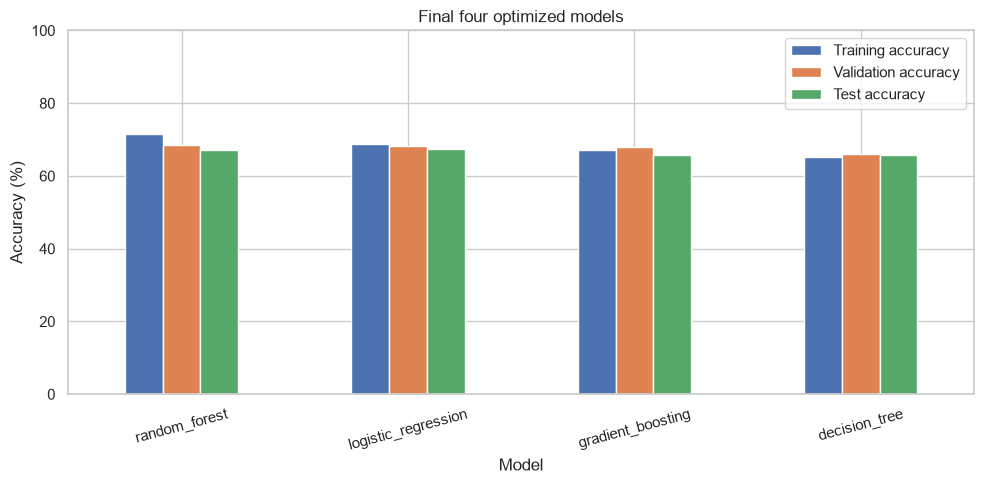

In [51]:
plot=comparison.set_index('Model')[['Training accuracy','Validation accuracy','Test accuracy']]*100
ax=plot.plot.bar(figsize=(10,5),ylim=(0,100),rot=15)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Final four optimized models')
plt.tight_layout()
plt.show()

## Fitting and reliability

All four retained models pass the existing fitting screens, including customer-disjoint CV. The 5-percentage-point gap rule is a heuristic, not proof of zero overfitting or underfitting. Small ranking differences do not establish statistical superiority. Validation and test have been inspected repeatedly; fresh future data is needed to confirm generalization. This notebook verifies the frozen selection without switching models based on test scores.


---

# Part 11: Customer Segmentation Using K-Means

*Source: `04_segmentation.ipynb`*

*Original cells: 23 | Code: 11 | Markdown: 12*


# Final customer segmentation

Run `02_preprocessing.ipynb` first. Install dependencies from the project root with `python -m pip install -r requirements.txt` before starting Jupyter.

This workflow uses the fixed-window customer table (1,696 customers), ten behavioral features, Yeo–Johnson transformation, robust scaling and 1st/99th percentile clipping. It compares k=2–6 and profiles the selected k=2 solution. Outcomes are observed activity, not Random Forest predictions, and never enter clustering. See [population definitions](../docs/customer_populations.md).


In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent
processed_dir = project_root / "data" / "processed"
customer_df = pd.read_csv(processed_dir / "customer_features.csv")
assert customer_df.CustomerID.notna().all() and customer_df.CustomerID.is_unique
assert customer_df.inactive_in_outcome_window.isin([0, 1]).all()
print(f"Eligible customers: {len(customer_df):,}")


Eligible customers: 1,696


## 1. Select behavioral inputs

In [53]:

# Features selected for Lens Two segmentation
features_v2 = [
    "frequency_count",
    "monetary_total",
    "monetary_avg",
    "product_diversity",
    "avg_quantity_per_invoice",
    "recency_days",
    "tenure_days",
    "return_rate",
    "active_months",
    "purchase_interval_avg",
    "purchases_per_month",
    "spend_per_month",
]

# Remove the redundant features identified in our previous analysis
features_v3 = [
    col for col in features_v2
    if col not in ["purchases_per_month", "spend_per_month"]
]

X_v3 = customer_df[features_v3].copy()

print("Number of segmentation features:", len(features_v3))
print("\nSelected features:")
print(features_v3)

print("\nMissing values by feature:")
print(X_v3.isna().sum())

print("\nFeature matrix shape:", X_v3.shape)

if not np.isfinite(X_v3.to_numpy()).all():
    raise ValueError("Clustering inputs must be finite and complete")


Number of segmentation features: 10

Selected features:
['frequency_count', 'monetary_total', 'monetary_avg', 'product_diversity', 'avg_quantity_per_invoice', 'recency_days', 'tenure_days', 'return_rate', 'active_months', 'purchase_interval_avg']

Missing values by feature:
frequency_count             0
monetary_total              0
monetary_avg                0
product_diversity           0
avg_quantity_per_invoice    0
recency_days                0
tenure_days                 0
return_rate                 0
active_months               0
purchase_interval_avg       0
dtype: int64

Feature matrix shape: (1696, 10)


## 2. Transform, scale and clip

In [54]:

from sklearn.preprocessing import PowerTransformer, RobustScaler
import pandas as pd

# 1. Reduce feature skewness while preserving negative values
power_transformer_v3 = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

X_v3_power = pd.DataFrame(
    power_transformer_v3.fit_transform(X_v3),
    columns=features_v3,
    index=X_v3.index
)

# 2. Scale features using robust statistics
robust_scaler_v3 = RobustScaler()

X_v3_scaled = pd.DataFrame(
    robust_scaler_v3.fit_transform(X_v3_power),
    columns=features_v3,
    index=X_v3.index
)

# 3. Limit extreme transformed values at the 1st and 99th percentiles
lower_v3 = X_v3_scaled.quantile(0.01)
upper_v3 = X_v3_scaled.quantile(0.99)

X_v3_winsorized = X_v3_scaled.clip(
    lower=lower_v3,
    upper=upper_v3,
    axis=1
)

print("Original feature matrix:", X_v3.shape)
print("Transformed matrix:", X_v3_winsorized.shape)
print("Missing values:", X_v3_winsorized.isna().sum().sum())

display(X_v3_winsorized.describe().round(3))


Original feature matrix: (1696, 10)
Transformed matrix: (1696, 10)
Missing values: 0


,frequency_count,monetary_total,monetary_avg,product_diversity,avg_quantity_per_invoice,recency_days,tenure_days,return_rate,active_months,purchase_interval_avg
count,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000,1696.000
mean,0.031,0.565,0.645,-0.029,0.472,-0.006,-0.060,0.168,-0.048,-0.003
std,0.487,2.039,2.345,0.776,1.753,0.647,0.599,0.573,0.899,0.736
min,-0.588,-0.713,-1.115,-1.979,-0.965,-1.276,-1.347,-0.383,-2.194,-1.754
25%,-0.588,-0.358,-0.408,-0.528,-0.405,-0.502,-0.533,-0.383,-0.510,-0.512
50%,0.000,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.000
75%,0.412,0.642,0.592,0.472,0.595,0.498,0.467,0.617,0.490,0.488
max,1.026,14.757,14.943,1.868,10.065,1.279,0.806,1.347,1.688,1.727


## 3. Compare candidate cluster counts

In [55]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

kmeans_results_v3 = []
kmeans_models_v3 = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_v3_winsorized)
    kmeans_models_v3[k] = model

    counts = pd.Series(labels).value_counts()

    kmeans_results_v3.append({
        "k": k,
        "silhouette": silhouette_score(
            X_v3_winsorized, labels
        ),
        "davies_bouldin": davies_bouldin_score(
            X_v3_winsorized, labels
        ),
        "smallest_cluster": counts.min(),
        "largest_cluster": counts.max(),
        "cluster_sizes": dict(sorted(counts.items())),
    })

kmeans_comparison_v3 = pd.DataFrame(kmeans_results_v3)

display(
    kmeans_comparison_v3.round(4)
)


,k,silhouette,davies_bouldin,smallest_cluster,largest_cluster,cluster_sizes
0,2,0.6895,0.9234,119,1577,"{0: 1577, 1: 119}"
1,3,0.5236,1.2252,45,1480,"{0: 1480, 1: 171, 2: 45}"
2,4,0.2480,1.2414,29,1059,"{0: 90, 1: 1059, 2: 518, 3: 29}"
3,5,0.2488,1.1261,26,997,"{0: 514, 1: 997, 2: 26, 3: 130, 4: 29}"
4,6,0.2156,1.1548,26,837,"{0: 27, 1: 837, 2: 116, 3: 79, 4: 26, 5: 611}"


## 4. Select and profile k=2

In [56]:
assert int(kmeans_comparison_v3.loc[kmeans_comparison_v3.silhouette.idxmax(), "k"]) == 2

# Select the two-cluster K-Means solution
kmeans_v3_k2 = kmeans_models_v3[2]
labels_v3_k2 = kmeans_v3_k2.labels_

# Keep customer IDs aligned with their cluster labels
segmented_customers_v3 = customer_df[
    ["CustomerID"]
].copy()

segmented_customers_v3["Cluster"] = labels_v3_k2

# Summarize segment sizes
cluster_sizes_v3 = (
    segmented_customers_v3["Cluster"]
    .value_counts()
    .sort_index()
    .rename("CustomerCount")
    .to_frame()
)

cluster_sizes_v3["CustomerPercentage"] = (
    cluster_sizes_v3["CustomerCount"]
    / len(segmented_customers_v3)
    * 100
)

print("Cluster sizes:")
display(cluster_sizes_v3.round(2))

# Profile segments using original, interpretable feature values
profile_features_v3 = [
    "frequency_count",
    "monetary_total",
    "monetary_avg",
    "product_diversity",
    "avg_quantity_per_invoice",
    "recency_days",
    "tenure_days",
    "return_rate",
    "active_months",
    "purchase_interval_avg",
]

profile_v3_k2 = (
    customer_df[profile_features_v3]
    .assign(Cluster=labels_v3_k2)
    .groupby("Cluster")
    .median()
    .T
)

print("Median customer behaviour by cluster:")
display(profile_v3_k2.round(2))


Cluster sizes:


,CustomerCount,CustomerPercentage
Cluster,,
0,1577,92.98
1,119,7.02


Median customer behaviour by cluster:


Cluster,0,1
frequency_count,5.00,9.00
monetary_total,1279.09,6943.48
monetary_avg,16.60,89.56
product_diversity,63.00,23.00
avg_quantity_per_invoice,9.31,46.00
recency_days,29.47,19.48
tenure_days,193.01,240.87
return_rate,0.01,0.02
active_months,4.00,6.00
purchase_interval_avg,2.01,4.16


## 5. Compare observed inactivity

In [57]:

# Compare the existing outcome with the two customer segments
retention_outcome = customer_df[
    ["CustomerID", "inactive_in_outcome_window"]
].copy()

segment_outcomes_v3 = segmented_customers_v3.merge(
    retention_outcome,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

segment_retention_summary_v3 = (
    segment_outcomes_v3
    .groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "size"),
        InactiveCount=("inactive_in_outcome_window", "sum"),
        InactivityRate=("inactive_in_outcome_window", "mean")
    )
)

segment_retention_summary_v3["InactivityRatePct"] = (
    segment_retention_summary_v3["InactivityRate"] * 100
)

display(
    segment_retention_summary_v3[
        ["CustomerCount", "InactiveCount", "InactivityRatePct"]
    ].round(2)
)


,CustomerCount,InactiveCount,InactivityRatePct
Cluster,,,
0,1577,476,30.18
1,119,32,26.89


## 6. Exploratory association

In [58]:

from scipy.stats import chi2_contingency

# Rows: clusters 0 and 1
# Columns: active and inactive customers
contingency_table = pd.crosstab(
    segment_outcomes_v3["Cluster"],
    segment_outcomes_v3["inactive_in_outcome_window"]
).reindex(columns=[0, 1], fill_value=0)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency table (0 = active, 1 = inactive):")
display(contingency_table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion: evidence of an association between cluster and inactivity.")
else:
    print("Conclusion: insufficient evidence of an association between cluster and inactivity.")

print("Minimum expected count:", expected.min())
print("Exploratory association only: no causal or predictive validation; outcomes were not clustering inputs.")


Contingency table (0 = active, 1 = inactive):


inactive_in_outcome_window,0,1
Cluster,,
0,1101,476
1,87,32


Chi-square statistic: 0.4257
Degrees of freedom: 1
P-value: 0.5141
Conclusion: insufficient evidence of an association between cluster and inactivity.
Minimum expected count: 35.6438679245283
Exploratory association only: no causal or predictive validation; outcomes were not clustering inputs.


## 7. Export final results

In [59]:

# Create output folders
outputs_dir = project_root / "outputs" / "segmentation"
outputs_dir.mkdir(parents=True, exist_ok=True)

# 1. Save customer-level segment assignments
segment_output = customer_df[
    ["CustomerID"]
].copy()

segment_output["Cluster"] = labels_v3_k2
segment_output = segment_output.merge(
    retention_outcome,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

segment_output.to_csv(
    outputs_dir / "customer_segments_kmeans_k2.csv",
    index=False
)

# 2. Save median profiles in original feature units
profile_v3_k2.to_csv(
    outputs_dir / "cluster_median_profiles_k2.csv"
)

# 3. Save cluster sizes
cluster_sizes_v3.to_csv(
    outputs_dir / "cluster_sizes_k2.csv"
)

# 4. Save inactivity comparison
segment_retention_summary_v3.to_csv(
    outputs_dir / "cluster_inactivity_summary_k2.csv"
)

# 5. Save clustering comparison
kmeans_comparison_v3.to_csv(
    outputs_dir / "kmeans_cluster_comparison_v3.csv",
    index=False
)

print("Lens Two outputs saved to:", outputs_dir)
print("\nSaved files:")

for path in sorted(outputs_dir.glob("*.csv")):
    print("-", path.name)

# Compatibility export: identical final assignments, no obsolete risk labels.
segment_output.to_csv(processed_dir / "customer_segments.csv", index=False)


Lens Two outputs saved to: D:\Year3\final\outputs\segmentation

Saved files:
- cluster_inactivity_summary_k2.csv
- cluster_median_profiles_k2.csv
- cluster_sizes_k2.csv
- customer_segments_kmeans_k2.csv
- kmeans_cluster_comparison_v3.csv


## 8. Visualize segment sizes

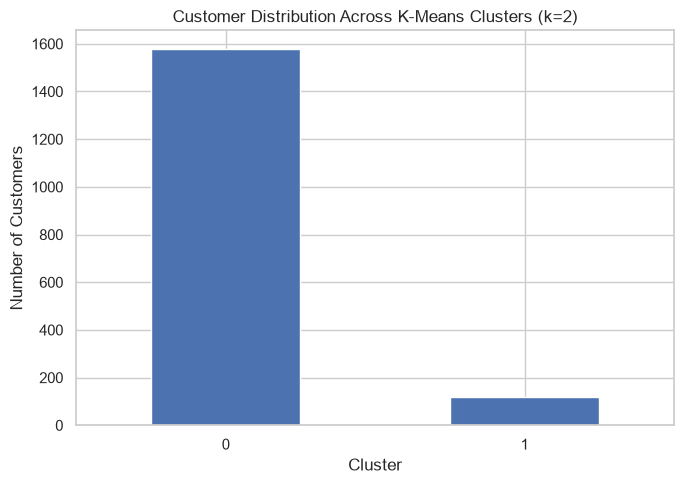

Customer distribution:


,CustomerCount,CustomerPercentage
Cluster,,
0,1577,92.983491
1,119,7.016509


In [60]:

import matplotlib.pyplot as plt

# Customer count by cluster
cluster_counts = (
    segmented_customers_v3["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))
cluster_counts.plot(kind="bar")
plt.title("Customer Distribution Across K-Means Clusters (k=2)")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Customer distribution:")
display(cluster_sizes_v3)


## 9. Visualize spending

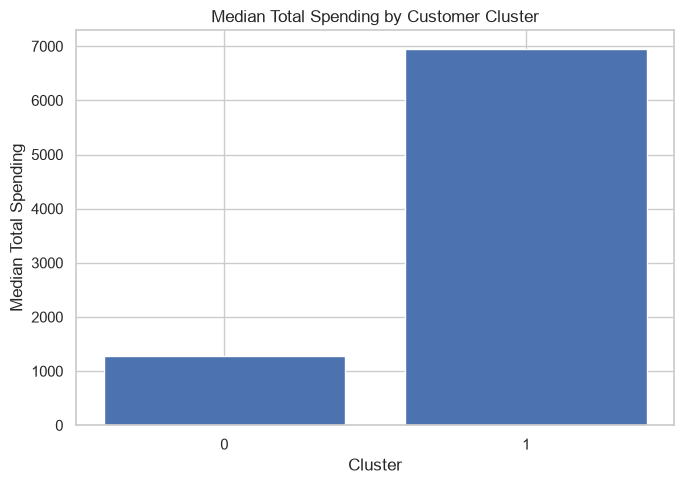

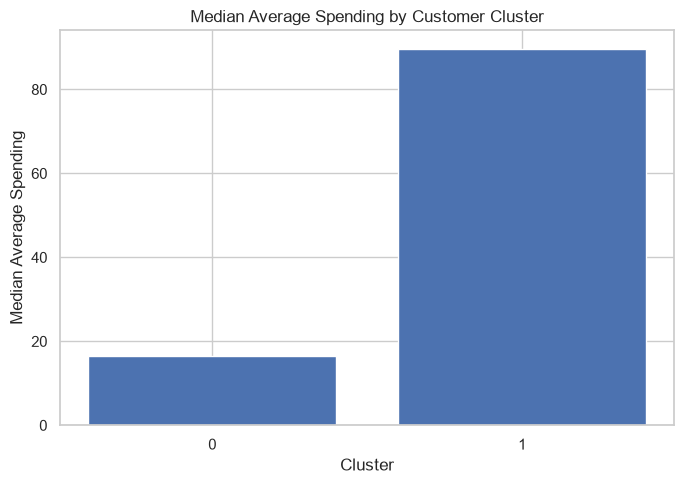

In [61]:

import matplotlib.pyplot as plt

spending_profile = (
    customer_df[["monetary_total", "monetary_avg"]]
    .assign(Cluster=labels_v3_k2)
    .groupby("Cluster")
    .median()
)

# Chart 1: Median total spending
plt.figure(figsize=(7, 5))
plt.bar(
    spending_profile.index.astype(str),
    spending_profile["monetary_total"]
)
plt.title("Median Total Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Total Spending")
plt.tight_layout()
plt.show()

# Chart 2: Median average spending
plt.figure(figsize=(7, 5))
plt.bar(
    spending_profile.index.astype(str),
    spending_profile["monetary_avg"]
)
plt.title("Median Average Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Average Spending")
plt.tight_layout()
plt.show()


## 10. Verify exports

In [62]:

from pathlib import Path
import pandas as pd

outputs_dir = project_root / "outputs" / "segmentation"

expected_files = [
    "customer_segments_kmeans_k2.csv",
    "cluster_median_profiles_k2.csv",
    "cluster_sizes_k2.csv",
    "cluster_inactivity_summary_k2.csv",
    "kmeans_cluster_comparison_v3.csv",
]

print("FILE CHECK")
for filename in expected_files:
    path = outputs_dir / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

segments_check = pd.read_csv(
    outputs_dir / "customer_segments_kmeans_k2.csv"
)

print("\nDATA QUALITY CHECK")
print("Rows:", len(segments_check))
print("Unique customers:", segments_check["CustomerID"].nunique())
print("Missing cluster labels:", segments_check["Cluster"].isna().sum())
print("Missing customer IDs:", segments_check["CustomerID"].isna().sum())
print("Duplicate customer IDs:", segments_check["CustomerID"].duplicated().sum())

assert len(segments_check) == len(customer_df)
assert segments_check["CustomerID"].nunique() == len(customer_df)
assert segments_check["Cluster"].notna().all()
assert segments_check["CustomerID"].notna().all()
assert not segments_check["CustomerID"].duplicated().any()

print("\nPASS: All 1,696 customers have one valid segment assignment.")

pd.testing.assert_frame_equal(segments_check, pd.read_csv(processed_dir / "customer_segments.csv"))
assert set(segments_check.CustomerID) == set(customer_df.CustomerID)


FILE CHECK
customer_segments_kmeans_k2.csv: OK
cluster_median_profiles_k2.csv: OK
cluster_sizes_k2.csv: OK
cluster_inactivity_summary_k2.csv: OK
kmeans_cluster_comparison_v3.csv: OK

DATA QUALITY CHECK
Rows: 1696
Unique customers: 1696
Missing cluster labels: 0
Missing customer IDs: 0
Duplicate customer IDs: 0

PASS: All 1,696 customers have one valid segment assignment.


## Interpretation and limits

The saved solution has 1,577 customers in cluster 0 and 119 in cluster 1 (silhouette approximately 0.6895). Cluster 1 has higher median spending, frequency and active months. Inactivity rates are approximately 30.18% and 26.89%; these are observed fixed-window outcomes, not predicted risk. Cluster numbers are identifiers, not validated marketing labels. Population, feature selection and clipping choices limit generalization; temporal and resampling stability remain untested.



---

# Part 12: Final Four Models Verification

*Source: `FINAL_Four_Optimized_Models.ipynb`*

*Original cells: 5 | Code: 3 | Markdown: 2*


# Final four optimized models

Logistic Regression, Decision Tree, Random Forest and Gradient Boosting. Each family retains its strongest eligible validation variant. Training/test accuracy is reported at its frozen threshold. All models pass the current fitting screens; this does not guarantee absence of overfitting or underfitting.

In [63]:
from pathlib import Path
import sys, json
import pandas as pd
import joblib
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root/'src'))
folder=root/'outputs/final_four'
selection=json.loads((folder/'selection.json').read_text())
print('Selected model:',selection['model'])
summary=pd.read_csv(folder/'accuracy_summary.csv')
display(summary.style.format({c:'{:.2%}' for c in summary.columns if 'accuracy' in c or 'gap' in c}))

Selected model: random_forest


,Model,Source,Threshold,Validation accuracy,CV accuracy,Threshold-matched CV gap,Training accuracy,Test accuracy,Train-test gap,Selected,Fit assessment
0,logistic_regression,optimized_logistic_regression,0.425000,68.29%,69.18%,0.81%,68.67%,67.37%,1.30%,False,Passes current screens; not proof of zero fitting risk
1,decision_tree,decision_tree,0.425000,66.10%,68.22%,1.16%,65.28%,65.69%,-0.41%,False,Passes current screens; not proof of zero fitting risk
2,random_forest,random_forest,0.425000,68.63%,69.59%,4.15%,71.56%,67.12%,4.43%,True,Passes current screens; not proof of zero fitting risk
3,gradient_boosting,gradient_boosting,0.375000,67.88%,69.54%,2.40%,67.21%,65.88%,1.33%,False,Passes current screens; not proof of zero fitting risk


In [64]:
from model_workflow import paths,load_features,matrix,TARGET,metrics
import numpy as np
data,fingerprint=load_features(paths(root)['processed'])
assert fingerprint==selection['fingerprint']
for _,row in summary.iterrows():
    bundle=joblib.load(folder/f'{row.Model}.joblib')
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy'),('test','Test accuracy')]:
        part=data[data.split.eq(split)]
        probabilities=bundle['pipeline'].predict_proba(matrix(part))[:,1]
        accuracy=metrics(row.Model,part[TARGET],probabilities,bundle['metadata']['Threshold'])['Accuracy']
        assert np.isclose(accuracy,row[column])
print('Verified all four saved models against reported train, validation and test accuracy.')

Verified all four saved models against reported train, validation and test accuracy.


In [65]:
selected=joblib.load(folder/f"{selection['model']}.joblib")
print('Prediction threshold:',selected['metadata']['Threshold'])
print(selection['limitations'])

Prediction threshold: 0.425
Validation and test were previously inspected. Scores are reused-holdout results; no guarantee of zero fitting risk.


Optimization uses fold-fitted preprocessing, regularization and customer-disjoint cross-validation. Fitting screens limit mean training–CV and training–validation gaps to 5 percentage points and require CV improvement over the majority baseline. Older experiments are historical; use only this notebook and `outputs/final_four` for the final four-model comparison.


---

# Part 13: Project Conclusion

## Summary of Findings

### Customer Retention Prediction

- **Selected Model:** Random Forest
- **Classification Threshold:** 0.425
- **Validation Accuracy:** 68.63%
- **Test Accuracy:** 67.12%
- **Selection Criterion:** Highest validation accuracy among fitting-eligible variants

### Customer Segmentation

- **Algorithm:** K-Means Clustering (K=2)
- **Customers Segmented:** 1,696
- **Cluster 0:** 1,577 customers (93%)
- **Cluster 1:** 119 customers (7%)
- **Silhouette Score:** 0.6895
- **Davies-Bouldin Score:** 0.9234

### Important Limitations

1. Validation and test sets were inspected during development (not fully independent)
2. Cluster membership was NOT significantly associated with inactivity (p=0.51)
3. Predictions are decision-support estimates, not guarantees
4. Model trained on 2010-2011 data may not reflect current patterns

---

## Project Artifacts

| Category | Location |
|----------|----------|
| Final Models | `outputs/final_four/` |
| Model Comparison | `outputs/final_four/model_comparison.csv` |
| Selection Metadata | `outputs/final_four/selection.json` |
| Segmentation Results | `outputs/segmentation/` |
| CV Evidence | `outputs/evidence/cross_validation/` |
| Processed Data | `data/processed/` |

---

*This notebook integrates the complete IT3091 Machine Learning project by Group 2026-DS-60.*

*All original analytical code, outputs, and visualizations have been preserved.*
